# Tahap 10 — kontribusi Pulomerak dengan satu LSTM

Target SO₂ Way Urang 30 menit berikutnya. S0 Way Urang, S1 tambahan SO₂ Pulomerak lag1 pada tiap langkah. Median C30, tanpa Curah Hujan, 48 slot berurutan, LSTM32, seed11/23/47, empat fold kalender tetap. Test akhir tidak dimuat/dievaluasi.

Training dilakukan oleh `scripts/lstm_interstation_stage10.py` dalam `.venv-lstm`, kemudian notebook ini dijalankan untuk mendokumentasikan checkpoint dan hasil tersimpan. Ini mencegah training ulang model yang telah selesai. Untuk reproduksi/resume, jalankan dari root proyek:

```powershell
.venv-lstm\Scripts\python.exe scripts/lstm_interstation_stage10.py
.venv-lstm\Scripts\python.exe scripts/summarize_interstation_stage10.py
.venv-lstm\Scripts\python.exe scripts/verify_interstation_stage10.py
```

Script training melewati model yang memiliki `complete.json` valid. Partial checkpoint memuat optimizer dan RNG untuk resume epoch berikutnya. Jangan mengubah implementasi/config terkunci atau menghapus checkpoint untuk memilih hasil. Notebook tidak memilih seed terbaik dan tidak menjalankan training tambahan.

In [1]:
from pathlib import Path
import json,sys,subprocess
import pandas as pd
from IPython.display import display,Markdown,Image
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
RUN=ROOT/'outputs/lstm_antarstasiun_tahap10'
sys.path.insert(0,str(ROOT/'scripts'))
from audit_quality import hashfile
cfg=json.loads((RUN/'config_locked.json').read_text(encoding='utf-8'))
t=json.loads((RUN/'tabel_hasil.json').read_text(encoding='utf-8'))
checks=json.loads((RUN/'checks.json').read_text())
assert checks['completed_models']==24 and not cfg['test_loaded'] and not cfg['test_evaluated']
print('Config SHA256:',hashfile(RUN/'config_locked.json'))
print('Environment:',cfg['environment'])
print('Kanal:',cfg['features'])
display(pd.DataFrame(t['Gate_sebelum_training']))


Config SHA256: 3fcd7cdd49c906ea7f2ad47ed261362c9f68e45cc03a4036318a321c3c035c7f
Environment: {'python': '3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)]', 'executable': 'C:\\Users\\INTAN\\airpollutan_SO2\\.venv-lstm\\Scripts\\python.exe', 'platform': 'Windows-11-10.0.26300-SP0', 'processor': 'Intel64 Family 6 Model 186 Stepping 2, GenuineIntel', 'device': 'cpu', 'cuda_available': False, 'torch_cuda_build': None, 'threads': 1, 'deterministic_algorithms': True, 'versions': {'torch': '2.15.0+cpu', 'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'ipykernel': '7.4.0'}}
Kanal: {'S0': ['SO2_origin', 'PM10_lag1', 'PM2.5_lag1', 'CO_lag1', 'O3_lag1', 'NO2_lag1', 'Kec.Angin_lag1', 'Kelembaban_lag1', 'Suhu_lag1', 'Tek.Udara_lag1', 'Sol.Rad_lag1', 'missing_asli_SO2_origin', 'missing_asli_PM10_lag1', 'missing_asli_PM2.5_lag1', 'missing_asli_CO_lag1', 'missing_asli_O3_lag1', 'missing_asli_NO2_lag1', 'missing_asli_Kec.Angin_lag

,Fold,Train bersama,Validasi internal bersama,Evaluasi bersama,Fit count sebelum gate,Lulus,Train internal akhir kalender,Validasi internal awal kalender,Validasi internal akhir kalender,Evaluasi awal kalender,Evaluasi akhir kalender
0,Fold_01,2679,860,4890,0,True,2025-04-12 23:30:00,2025-04-13 00:00:00,2025-04-30 23:30:00,2025-05-01 00:00:00,2025-08-12 13:30:00
1,Fold_02,6822,1607,4969,0,True,2025-07-10 00:30:00,2025-07-10 01:00:00,2025-08-12 13:30:00,2025-08-12 14:00:00,2025-11-24 03:00:00
2,Fold_03,11042,2356,4969,0,True,2025-10-06 01:00:00,2025-10-06 01:30:00,2025-11-24 03:00:00,2025-11-24 03:30:00,2026-03-07 16:30:00
3,Fold_04,15267,3100,4969,0,True,2026-01-02 01:30:00,2026-01-02 02:00:00,2026-03-07 16:30:00,2026-03-07 17:00:00,2026-06-19 06:00:00


## Kausalitas dan kesetaraan sampel

15% akhir kalender train dipakai untuk early stopping. Median prefix diperbarui30hari selama train internal lalu dibekukan. Kanal donor tertunda sebelum imputasi; bank tidak melampaui informasi yang tersedia. Scaler numerik pada slot unik train internal bersama, indikator tetap0/1. Target asli distandardisasi train dan inverse sebelum penilaian. Purge melarang target melintasi bagian; konteks historis yang sudah tersedia boleh dipakai. Tidak memadatkan waktu atau mengisi target.

In [2]:
for name in ['Alur_sampel','Distribusi_target','Keluar_irisan','Sampel_tersisih','Purge_batas']:
    print(name);display(pd.DataFrame(t[name]))


Alur_sampel
Distribusi_target
Keluar_irisan
Sampel_tersisih
Purge_batas


,Fold,Bagian,Skenario,Slot kalender target,Target asli seluruh bagian,Kandidat origin setelah warmup buffer purge,Target asli sebelum sekuens,Origin finite setelah imputasi,Sekuens lengkap 48 slot,Sesudah irisan,Keluar karena sekuens,Keluar karena irisan
0,Fold_01,inner_train,S0,4896,3064,3407,2679,2679,2679,2679,0,0
1,Fold_01,inner_train,S1,4896,3064,3407,2679,2679,2679,2679,0,0
2,Fold_01,inner_validation,S0,864,860,864,860,860,860,860,0,0
3,Fold_01,inner_validation,S1,864,860,864,860,860,860,860,0,0
4,Fold_01,evaluation,S0,4972,4890,4972,4890,4890,4890,4890,0,0
5,Fold_01,evaluation,S1,4972,4890,4972,4890,4890,4890,4890,0,0
6,Fold_02,inner_train,S0,9122,7207,7633,6822,6822,6822,6822,0,0
7,Fold_02,inner_train,S1,9122,7207,7633,6822,6822,6822,6822,0,0
8,Fold_02,inner_validation,S0,1610,1607,1610,1607,1607,1607,1607,0,0
9,Fold_02,inner_validation,S1,1610,1607,1610,1607,1607,1607,1607,0,0


,Fold,Bagian,Domain,Target awal,Target akhir,Minimum,P1,P25,Median,P75,P99,Maksimum,N,Mean,SD,SO2 lebih2.14
0,Fold_01,inner_train,target asli kalender,2025-01-02 11:30:00,2025-04-12 23:30:00,0.92,1.3100,1.47,44.97,45.68,77.4622,80.71,3064,31.881794,23.881200,1973
1,Fold_01,inner_train,target asli sebelum sekuens,2025-02-13 19:00:00,2025-04-12 23:30:00,1.24,1.3300,1.45,45.15,45.80,77.6454,80.71,2679,36.231391,22.398111,1972
2,Fold_01,inner_train,bersama digunakan,2025-02-13 19:00:00,2025-04-12 23:30:00,1.24,1.3300,1.45,45.15,45.80,77.6454,80.71,2679,36.231391,22.398111,1972
3,Fold_01,inner_validation,target asli kalender,2025-04-13 00:00:00,2025-04-30 23:30:00,43.72,43.9977,45.02,45.45,45.84,46.8946,47.29,860,45.436721,0.619540,860
4,Fold_01,inner_validation,target asli sebelum sekuens,2025-04-13 00:00:00,2025-04-30 23:30:00,43.72,43.9977,45.02,45.45,45.84,46.8946,47.29,860,45.436721,0.619540,860
5,Fold_01,inner_validation,bersama digunakan,2025-04-13 00:00:00,2025-04-30 23:30:00,43.72,43.9977,45.02,45.45,45.84,46.8946,47.29,860,45.436721,0.619540,860
6,Fold_01,evaluation,target asli kalender,2025-05-01 00:00:00,2025-08-12 13:30:00,1.07,1.2500,1.56,43.85,45.38,46.7411,47.81,4890,23.580558,21.929684,2456
7,Fold_01,evaluation,target asli sebelum sekuens,2025-05-01 00:00:00,2025-08-12 13:30:00,1.07,1.2500,1.56,43.85,45.38,46.7411,47.81,4890,23.580558,21.929684,2456
8,Fold_01,evaluation,bersama digunakan,2025-05-01 00:00:00,2025-08-12 13:30:00,1.07,1.2500,1.56,43.85,45.38,46.7411,47.81,4890,23.580558,21.929684,2456
9,Fold_02,inner_train,target asli kalender,2025-01-02 11:30:00,2025-07-10 00:30:00,0.92,1.3100,1.76,45.12,45.71,76.1894,80.71,7207,34.627666,20.612354,5289


,Fold,Bagian,Skenario,Alasan,N,Minimum,P1,P25,Median,P75,P99,Maksimum,Mean,SD,SO2 lebih2.14
0,Fold_01,inner_train,S0,irisan antar-skenario,0,None,None,None,None,None,None,None,None,None,0
1,Fold_01,inner_train,S1,irisan antar-skenario,0,None,None,None,None,None,None,None,None,None,0
2,Fold_01,inner_validation,S0,irisan antar-skenario,0,None,None,None,None,None,None,None,None,None,0
3,Fold_01,inner_validation,S1,irisan antar-skenario,0,None,None,None,None,None,None,None,None,None,0
4,Fold_01,evaluation,S0,irisan antar-skenario,0,None,None,None,None,None,None,None,None,None,0
5,Fold_01,evaluation,S1,irisan antar-skenario,0,None,None,None,None,None,None,None,None,None,0
6,Fold_02,inner_train,S0,irisan antar-skenario,0,None,None,None,None,None,None,None,None,None,0
7,Fold_02,inner_train,S1,irisan antar-skenario,0,None,None,None,None,None,None,None,None,None,0
8,Fold_02,inner_validation,S0,irisan antar-skenario,0,None,None,None,None,None,None,None,None,None,0
9,Fold_02,inner_validation,S1,irisan antar-skenario,0,None,None,None,None,None,None,None,None,None,0


,Fold,Bagian,Alasan,Slot tersisih,Target awal,Target akhir,N,Minimum,P1,P25,Median,P75,P99,Maksimum,Mean,SD,SO2 lebih2.14
0,Fold_01,inner_train,target kosong,1832,2025-01-01 00:00:00,2025-04-06 02:00:00,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,Fold_01,inner_train,histori sebelum grid,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,Fold_01,inner_train,warmup statistik,385,2025-01-02 11:30:00,2025-01-24 08:00:00,385,0.92,1.1352,1.52,1.63,1.72,2.0548,2.15,1.615379,0.180945,1
3,Fold_01,inner_train,buffer setelah warmup,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,Fold_01,inner_train,sesudah warmup tetapi tidak masuk irisan,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
5,Fold_01,inner_validation,target kosong,4,2025-04-15 09:00:00,2025-04-28 03:30:00,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
6,Fold_01,inner_validation,histori sebelum grid,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
7,Fold_01,inner_validation,warmup statistik,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
8,Fold_01,inner_validation,buffer setelah warmup,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
9,Fold_01,inner_validation,sesudah warmup tetapi tidak masuk irisan,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


,Fold,Bagian yang dilarang,Origin dipurge,Timestamp target,SO2 target asli,Target asli teramati,Penjelasan
0,Fold_01,inner_train,2025-04-12 23:30:00,2025-04-13 00:00:00,44.68,True,Dikeluarkan dari bagian sebelumnya; menjadi ka...
1,Fold_01,inner_validation,2025-04-30 23:30:00,2025-05-01 00:00:00,45.48,True,Dikeluarkan dari bagian sebelumnya; menjadi ka...
2,Fold_02,inner_train,2025-07-10 00:30:00,2025-07-10 01:00:00,1.72,True,Dikeluarkan dari bagian sebelumnya; menjadi ka...
3,Fold_02,inner_validation,2025-08-12 13:30:00,2025-08-12 14:00:00,1.47,True,Dikeluarkan dari bagian sebelumnya; menjadi ka...
4,Fold_03,inner_train,2025-10-06 01:00:00,2025-10-06 01:30:00,1.72,True,Dikeluarkan dari bagian sebelumnya; menjadi ka...
5,Fold_03,inner_validation,2025-11-24 03:00:00,2025-11-24 03:30:00,1.61,True,Dikeluarkan dari bagian sebelumnya; menjadi ka...
6,Fold_04,inner_train,2026-01-02 01:30:00,2026-01-02 02:00:00,1.84,True,Dikeluarkan dari bagian sebelumnya; menjadi ka...
7,Fold_04,inner_validation,2026-03-07 16:30:00,2026-03-07 17:00:00,1.46,True,Dikeluarkan dari bagian sebelumnya; menjadi ka...


## Seluruh seed dan checkpoint

Satu layer LSTM32 dan Dense linear, Adam0.001, batch64, MSE, maksimal50epoch, patience8, restore best internal. Semua24 model disertakan. Cakupan menggunakan seluruh target asli teramati sebagai denominator. RMSE gabungan dihitung dari error OOF perseed, bukan mean RMSE fold.

In [3]:
complete=sorted(RUN.glob('Fold_*/S*_seed*/complete.json'))
assert len(complete)==24
for file in complete:
    record=json.loads(file.read_text(encoding='utf-8'))
    for name,sha in record['files_sha256'].items():assert hashfile(file.parent/name)==sha
for name in ['Training_dan_waktu','Skor_fold_seed','Gabungan_per_seed','Ringkasan','Perubahan_S1_vs_S0']:
    print(name);display(pd.DataFrame(t[name]))


Training_dan_waktu
Skor_fold_seed
Gabungan_per_seed
Ringkasan
Perubahan_S1_vs_S0


,Fold,Skenario,Seed,Epoch dijalankan,Epoch terbaik,Internal MSE standar terbaik,Fit early stopping detik,Predict detik,Waktu fit definisi,N train bersama,N validasi internal bersama,Jumlah parameter
0,Fold_01,S0,11,25,17,0.000797,30.123244,0.721320,Jumlah durasi epoch train+validasi internal; t...,2679,860,7201
1,Fold_01,S0,23,27,19,0.000803,31.895839,0.789712,Jumlah durasi epoch train+validasi internal; t...,2679,860,7201
2,Fold_01,S0,47,44,36,0.000815,51.430627,0.754926,Jumlah durasi epoch train+validasi internal; t...,2679,860,7201
3,Fold_01,S1,11,34,26,0.000814,38.882069,0.669072,Jumlah durasi epoch train+validasi internal; t...,2679,860,7457
4,Fold_01,S1,23,31,23,0.000824,36.655546,0.962169,Jumlah durasi epoch train+validasi internal; t...,2679,860,7457
5,Fold_01,S1,47,33,25,0.000833,38.896089,0.668279,Jumlah durasi epoch train+validasi internal; t...,2679,860,7457
6,Fold_02,S0,11,16,8,0.001217,42.021976,0.162449,Jumlah durasi epoch train+validasi internal; t...,6822,1607,7201
7,Fold_02,S0,23,36,28,0.001005,108.757584,0.715620,Jumlah durasi epoch train+validasi internal; t...,6822,1607,7201
8,Fold_02,S0,47,16,8,0.001435,46.192421,0.671870,Jumlah durasi epoch train+validasi internal; t...,6822,1607,7201
9,Fold_02,S1,11,25,17,0.000599,68.229840,0.683931,Jumlah durasi epoch train+validasi internal; t...,6822,1607,7457


,Fold,Seed,Skenario,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Fold_01,11,S0,mandiri,4890,4890,100.0,14.088429,20.431628,13.834207,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
1,Fold_01,11,S0,bersama,4890,4890,100.0,14.088429,20.431628,13.834207,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
2,Fold_01,11,S1,mandiri,4890,4890,100.0,16.103345,22.777251,15.855943,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
3,Fold_01,11,S1,bersama,4890,4890,100.0,16.103345,22.777251,15.855943,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
4,Fold_01,11,Persistence,mandiri,4890,4890,100.0,0.430562,0.885256,0.009049,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
...,...,...,...,...,...,...,...,...,...,...,...,...
67,Fold_04,47,S0,bersama,4969,4969,100.0,0.157629,0.263519,0.079551,10,43cde718d85be72d2a1b783dfb4909258f1c10f2f86628...
68,Fold_04,47,S1,mandiri,4969,4969,100.0,23.968101,27.139646,23.968101,0,43cde718d85be72d2a1b783dfb4909258f1c10f2f86628...
69,Fold_04,47,S1,bersama,4969,4969,100.0,23.968101,27.139646,23.968101,0,43cde718d85be72d2a1b783dfb4909258f1c10f2f86628...
70,Fold_04,47,Persistence,mandiri,4969,4969,100.0,0.115935,0.149092,0.000024,0,43cde718d85be72d2a1b783dfb4909258f1c10f2f86628...


,Fold,Seed,Skenario,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Gabungan_OOF,11,S0,mandiri,19797,19797,100.0,3.723031,10.169410,3.511675,26,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
1,Gabungan_OOF,11,S0,bersama,19797,19797,100.0,3.723031,10.169410,3.511675,26,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
2,Gabungan_OOF,11,S1,mandiri,19797,19797,100.0,8.205886,14.423154,7.984151,21,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
3,Gabungan_OOF,11,S1,bersama,19797,19797,100.0,8.205886,14.423154,7.984151,21,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
4,Gabungan_OOF,11,Persistence,mandiri,19797,19797,100.0,0.206335,0.464340,0.002240,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
5,Gabungan_OOF,11,Persistence,bersama,19797,19797,100.0,0.206335,0.464340,0.002240,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
6,Gabungan_OOF,23,S0,mandiri,19797,19797,100.0,4.181421,10.894457,3.996841,60,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
7,Gabungan_OOF,23,S0,bersama,19797,19797,100.0,4.181421,10.894457,3.996841,60,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
8,Gabungan_OOF,23,S1,mandiri,19797,19797,100.0,9.249586,16.174262,8.967543,11,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
9,Gabungan_OOF,23,S1,bersama,19797,19797,100.0,9.249586,16.174262,8.967543,11,1663821d30ee4523fd8c636c175f3570cf6976594a170f...


,Fold,Skenario,Domain,Seed N,MAE mean,MAE SD seed,MAE min,MAE max,RMSE mean,RMSE SD seed,RMSE min,RMSE max,Bias mean,Bias SD seed,Bias min,Bias max,Cakupan persen mean,Cakupan persen SD seed,Cakupan persen min,Cakupan persen max,Prediksi negatif mean,Prediksi negatif SD seed,Prediksi negatif min,Prediksi negatif max
0,Fold_01,S0,bersama,3,16.317958,2.744570e+00,14.088429,19.383252,23.290559,3.778002,20.431628,27.573651,16.057695,2.746188,13.834207,19.127404,100.0,0.0,100.0,100.0,0.000000,0.000000,0.0,0.0
1,Fold_01,S1,bersama,3,16.349924,9.890141e-01,15.507528,17.438899,23.225760,1.566510,21.932423,24.967605,16.099012,0.975512,15.268016,17.173076,100.0,0.0,100.0,100.0,0.000000,0.000000,0.0,0.0
2,Fold_01,Persistence,bersama,3,0.430562,0.000000e+00,0.430562,0.430562,0.885256,0.000000,0.885256,0.885256,0.009049,0.000000,0.009049,0.009049,100.0,0.0,100.0,100.0,0.000000,0.000000,0.0,0.0
3,Fold_02,S0,bersama,3,0.861119,2.529122e-01,0.696230,1.152306,1.158641,0.298598,0.911808,1.490542,0.526030,0.392686,0.229197,0.971297,100.0,0.0,100.0,100.0,55.666667,34.004902,22.0,90.0
4,Fold_02,S1,bersama,3,0.462806,8.407931e-02,0.365721,0.511799,0.650585,0.150980,0.483383,0.776936,0.005261,0.091688,-0.096298,0.081944,100.0,0.0,100.0,100.0,21.666667,16.010413,6.0,38.0
5,Fold_02,Persistence,bersama,3,0.142954,0.000000e+00,0.142954,0.142954,0.183682,0.000000,0.183682,0.183682,-0.000020,0.000000,-0.000020,-0.000020,100.0,0.0,100.0,100.0,0.000000,0.000000,0.0,0.0
6,Fold_03,S0,bersama,3,0.127222,6.897712e-03,0.121554,0.134902,0.196692,0.031285,0.167534,0.229740,-0.003355,0.020411,-0.018705,0.019808,100.0,0.0,100.0,100.0,3.000000,1.732051,2.0,5.0
7,Fold_03,S1,bersama,3,3.634552,3.774033e-01,3.359977,4.064909,9.973685,0.769149,9.458665,10.857817,3.484089,0.435351,3.191693,3.984418,100.0,0.0,100.0,100.0,2.666667,2.309401,0.0,4.0
8,Fold_03,Persistence,bersama,3,0.139453,0.000000e+00,0.139453,0.139453,0.178418,0.000000,0.178418,0.178418,0.000016,0.000000,0.000016,0.000016,100.0,0.0,100.0,100.0,0.000000,0.000000,0.0,0.0
9,Fold_04,S0,bersama,3,0.138461,2.359110e-02,0.112114,0.157629,0.234072,0.057367,0.167962,0.270735,0.030441,0.044145,-0.005944,0.079551,100.0,0.0,100.0,100.0,5.000000,4.358899,2.0,10.0


,Fold,Seed,N identik,Perbaikan MAE persen,Perbaikan RMSE persen,Delta MAE S1 minus S0,Delta RMSE S1 minus S0,Delta Bias S1 minus S0,Delta MAE S0 minus persistence,Delta MAE S1 minus persistence,Delta RMSE S0 minus persistence,Delta RMSE S1 minus persistence
0,Fold_01,11,4890,-14.301920,-11.480352,2.014916,2.345623,2.021736,13.657867,15.672782,19.546372,21.891995
1,Fold_01,23,4890,-12.638420,-14.182521,1.956705,3.101207,1.961602,15.051631,17.008336,20.981143,24.082349
2,Fold_01,47,4890,19.995222,20.458764,-3.875724,-5.641228,-3.859387,18.952690,15.076966,26.688395,21.047167
3,Fold_02,11,4969,30.473265,35.594793,-0.223924,-0.382136,-0.347459,0.591868,0.367944,0.889892,0.507755
4,Fold_02,23,4969,68.261832,67.569968,-0.786585,-1.007159,-1.067595,1.009352,0.222767,1.306861,0.299702
5,Fold_02,47,4969,26.489972,14.791765,-0.184431,-0.134873,-0.147254,0.553276,0.368844,0.728127,0.593254
6,Fold_03,11,4969,-3244.120532,-6380.975218,3.943355,10.690283,4.003124,-0.017899,3.925457,-0.010884,10.679399
7,Fold_03,23,4969,-2678.353931,-4881.558531,3.353561,9.411770,3.202862,-0.014243,3.339318,0.014385,9.426155
8,Fold_03,47,4969,-2390.682305,-4017.114924,3.225075,9.228925,3.256347,-0.004551,3.220525,0.051322,9.280247
9,Fold_04,11,4969,-10844.160186,-8317.257782,12.157837,13.969821,12.173542,-0.003821,12.154016,0.018870,13.988691


Ketersediaan_donor
Ridge_timestamp_identik
Transisi_per_seed
Verifikasi tanpa training: {'config_sha256': '3fcd7cdd49c906ea7f2ad47ed261362c9f68e45cc03a4036318a321c3c035c7f', 'preflight_only': False, 'model_fits_in_verifier': 0, 'folds': [{'Fold': 'Fold_01', 'causal_prefix_verified': True, 'train_scalers_verified': True, 'sequence_and_original_flags_verified': True, 'train_common_N': 2679, 'internal_common_N': 860, 'evaluation_common_N': 4890}, {'Fold': 'Fold_02', 'causal_prefix_verified': True, 'train_scalers_verified': True, 'sequence_and_original_flags_verified': True, 'train_common_N': 6822, 'internal_common_N': 1607, 'evaluation_common_N': 4969}, {'Fold': 'Fold_03', 'causal_prefix_verified': True, 'train_scalers_verified': True, 'sequence_and_original_flags_verified': True, 'train_common_N': 11042, 'internal_common_N': 2356, 'evaluation_common_N': 4969}, {'Fold': 'Fold_04', 'causal_prefix_verified': True, 'train_scalers_verified': True, 'sequence_and_original_flags_verified': True,

,Fold,Bagian,N sekuens bersama,Posisi fitur donor,Posisi donor missing asli diimputasi,Proporsi posisi donor diimputasi persen,Sekuens dengan donor diimputasi N,Sekuens dengan donor diimputasi persen,Usia donor origin median menit,Usia donor origin P95 menit,Usia donor origin maksimum menit
0,Fold_01,inner_train,2679,128592,23320,18.134876,608,22.695035,30.0,6783.0,10800.0
1,Fold_01,inner_validation,860,41280,10200,24.709302,330,38.372093,30.0,15151.5,16440.0
2,Fold_01,evaluation,4890,234720,1008,0.429448,473,9.672802,30.0,30.0,150.0
3,Fold_02,inner_train,6822,327456,34480,10.529659,1363,19.979478,30.0,6178.5,16440.0
4,Fold_02,inner_validation,1607,77136,48,0.062228,48,2.986932,30.0,30.0,60.0
5,Fold_02,evaluation,4969,238512,240,0.100624,193,3.884081,30.0,30.0,90.0
6,Fold_03,inner_train,11042,530016,34720,6.550746,1556,14.091650,30.0,2130.0,16440.0
7,Fold_03,inner_validation,2356,113088,48,0.042445,48,2.037351,30.0,30.0,60.0
8,Fold_03,evaluation,4969,238512,65832,27.601127,1834,36.908835,30.0,22998.0,30450.0
9,Fold_04,inner_train,15267,732816,34960,4.770638,1749,11.456082,30.0,30.0,16440.0


,Fold,Seed,Skenario,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Fold_01,11,S0,LSTM dan Ridge timestamp identik,4890,4890,100.0,14.088429,20.431628,13.834207,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
1,Fold_01,11,S1,LSTM dan Ridge timestamp identik,4890,4890,100.0,16.103345,22.777251,15.855943,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
2,Fold_01,11,S0_Ridge,LSTM dan Ridge timestamp identik,4890,4890,100.0,17.245739,40.229392,-11.924223,1317,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
3,Fold_01,11,S1_Ridge,LSTM dan Ridge timestamp identik,4890,4890,100.0,17.347303,40.464950,-11.970927,1311,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
4,Fold_01,11,Persistence,LSTM dan Ridge timestamp identik,4890,4890,100.0,0.430562,0.885256,0.009049,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
...,...,...,...,...,...,...,...,...,...,...,...,...
70,Gabungan_OOF,47,S0,LSTM dan Ridge timestamp identik,19797,19797,100.0,5.035978,13.712783,4.807072,105,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
71,Gabungan_OOF,47,S1,LSTM dan Ridge timestamp identik,19797,19797,100.0,10.818213,18.063786,10.630120,42,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
72,Gabungan_OOF,47,S0_Ridge,LSTM dan Ridge timestamp identik,19797,19797,100.0,4.370998,19.996605,-2.982118,1321,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
73,Gabungan_OOF,47,S1_Ridge,LSTM dan Ridge timestamp identik,19797,19797,100.0,4.400311,20.113696,-2.972787,1315,1663821d30ee4523fd8c636c175f3570cf6976594a170f...


,Periode,Fold,Seed,Skenario,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,sebelum transisi,Fold_01,11,S0,jendela transisi ±72jam,144,144,100.0,0.442596,0.569922,0.049806,0,ace277a76617578e0e73d01ab4c5ad2a7dfacce77d67c3...
1,sebelum transisi,Fold_01,11,S1,jendela transisi ±72jam,144,144,100.0,0.448173,0.571850,0.075289,0,ace277a76617578e0e73d01ab4c5ad2a7dfacce77d67c3...
2,sebelum transisi,Fold_01,11,Persistence,jendela transisi ±72jam,144,144,100.0,0.602500,0.783946,-0.005556,0,ace277a76617578e0e73d01ab4c5ad2a7dfacce77d67c3...
3,sesudah transisi,Fold_01,11,S0,jendela transisi ±72jam,145,145,100.0,27.132007,28.113190,27.132007,0,67af315c62a95e904130f4d21924c94ae867784d784a9b...
4,sesudah transisi,Fold_01,11,S1,jendela transisi ±72jam,145,145,100.0,31.834771,32.279348,31.834771,0,67af315c62a95e904130f4d21924c94ae867784d784a9b...
5,sesudah transisi,Fold_01,11,Persistence,jendela transisi ±72jam,145,145,100.0,0.465034,3.600567,0.301586,0,67af315c62a95e904130f4d21924c94ae867784d784a9b...
6,sebelum transisi,Fold_01,23,S0,jendela transisi ±72jam,144,144,100.0,0.465829,0.586869,0.039263,0,ace277a76617578e0e73d01ab4c5ad2a7dfacce77d67c3...
7,sebelum transisi,Fold_01,23,S1,jendela transisi ±72jam,144,144,100.0,0.446582,0.577007,0.080649,0,ace277a76617578e0e73d01ab4c5ad2a7dfacce77d67c3...
8,sebelum transisi,Fold_01,23,Persistence,jendela transisi ±72jam,144,144,100.0,0.602500,0.783946,-0.005556,0,ace277a76617578e0e73d01ab4c5ad2a7dfacce77d67c3...
9,sesudah transisi,Fold_01,23,S0,jendela transisi ±72jam,145,145,100.0,30.509249,30.912249,30.509249,0,67af315c62a95e904130f4d21924c94ae867784d784a9b...


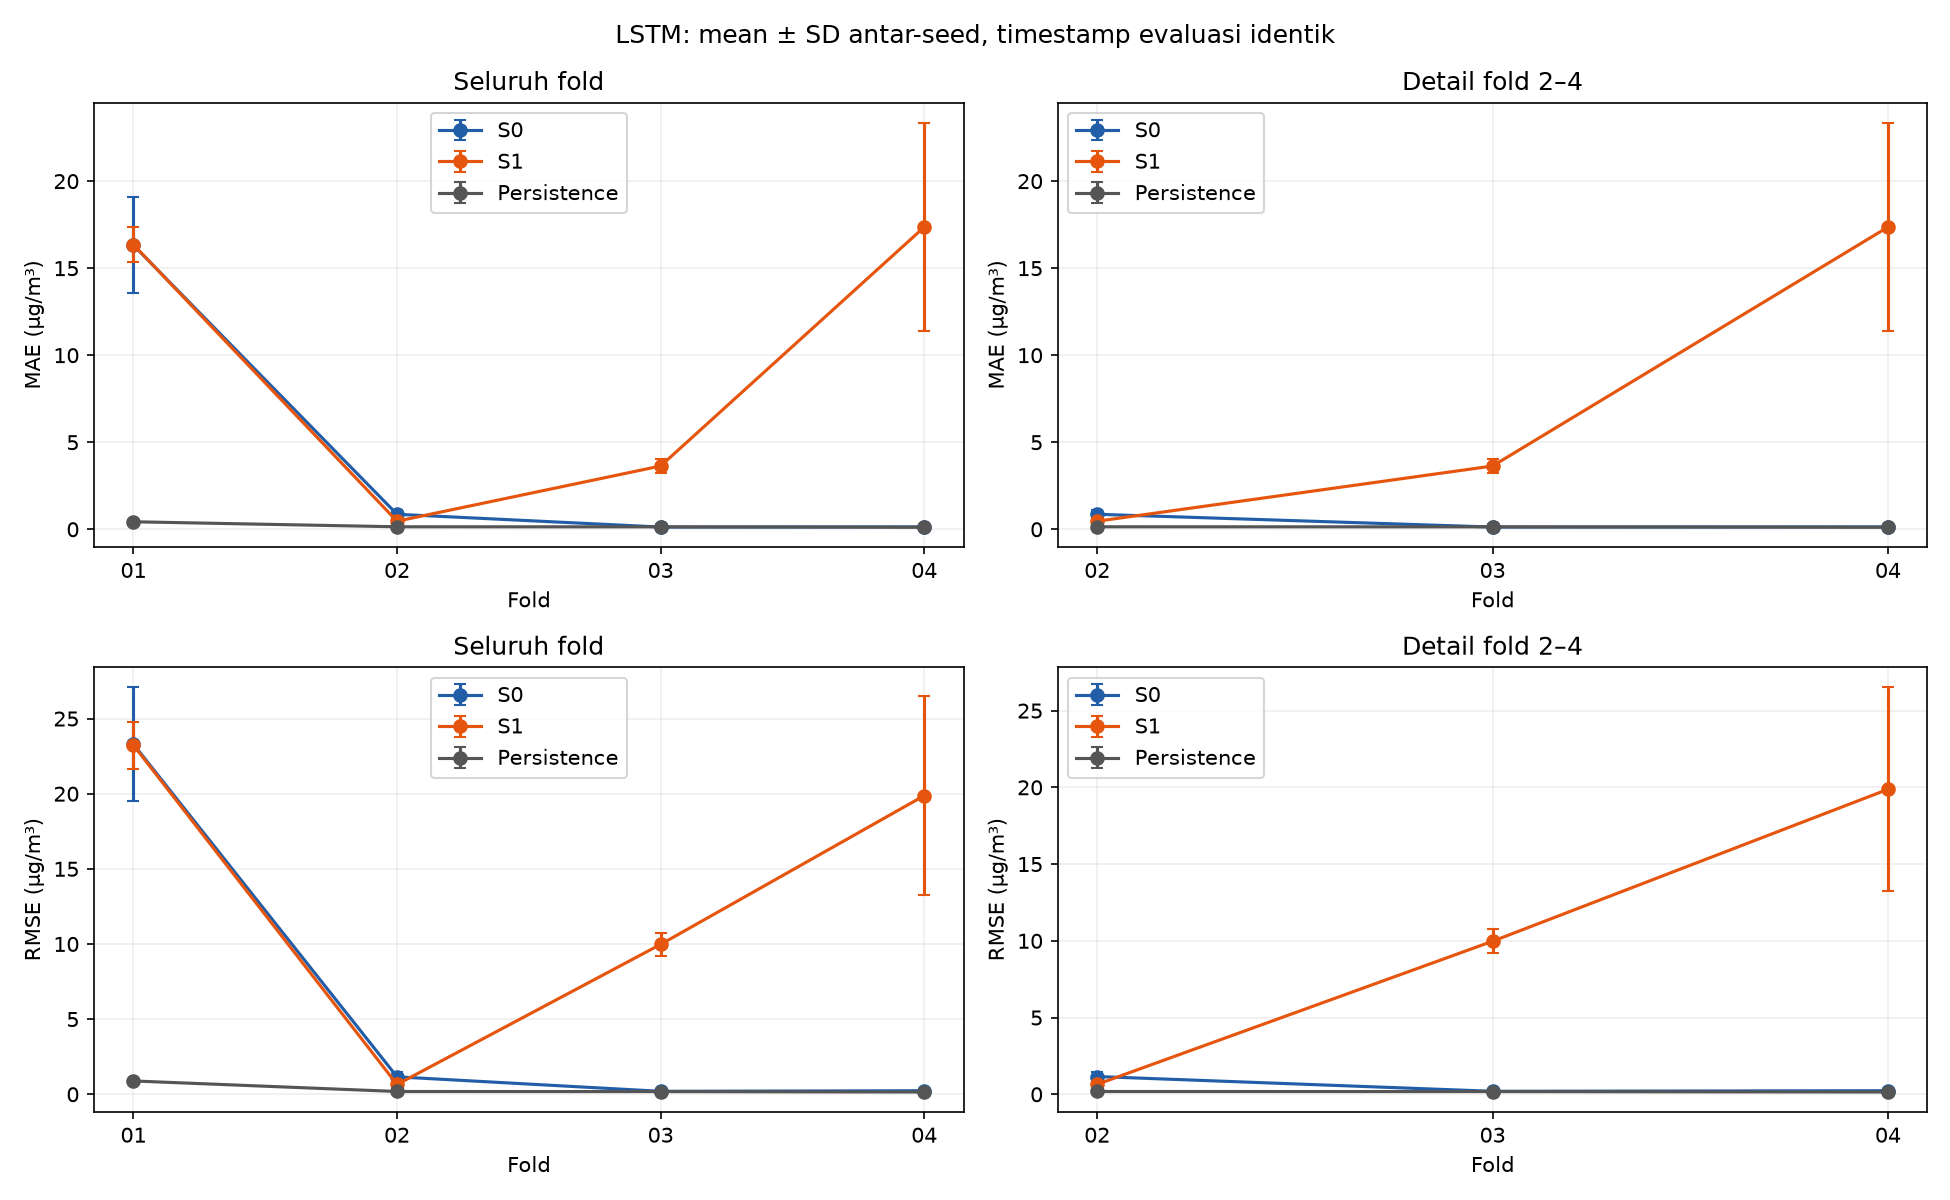

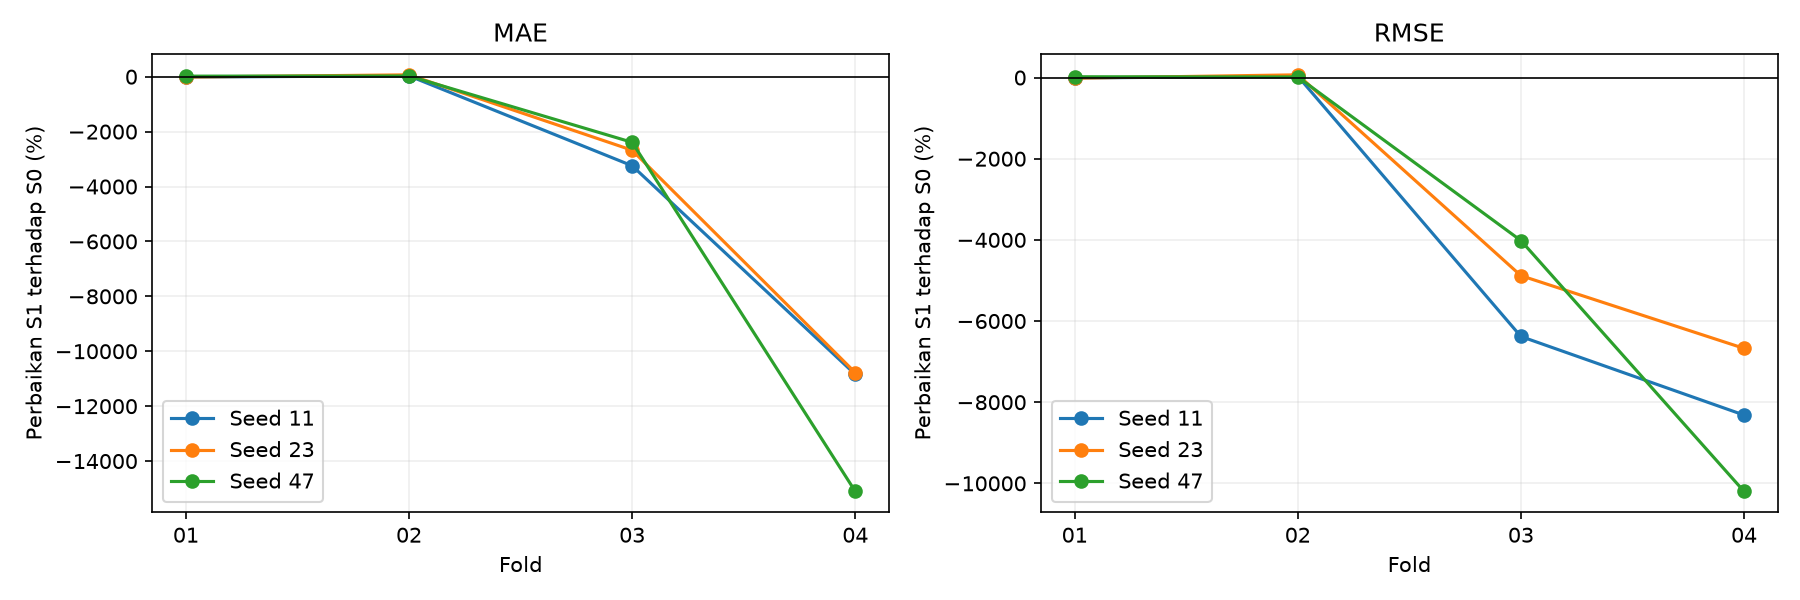

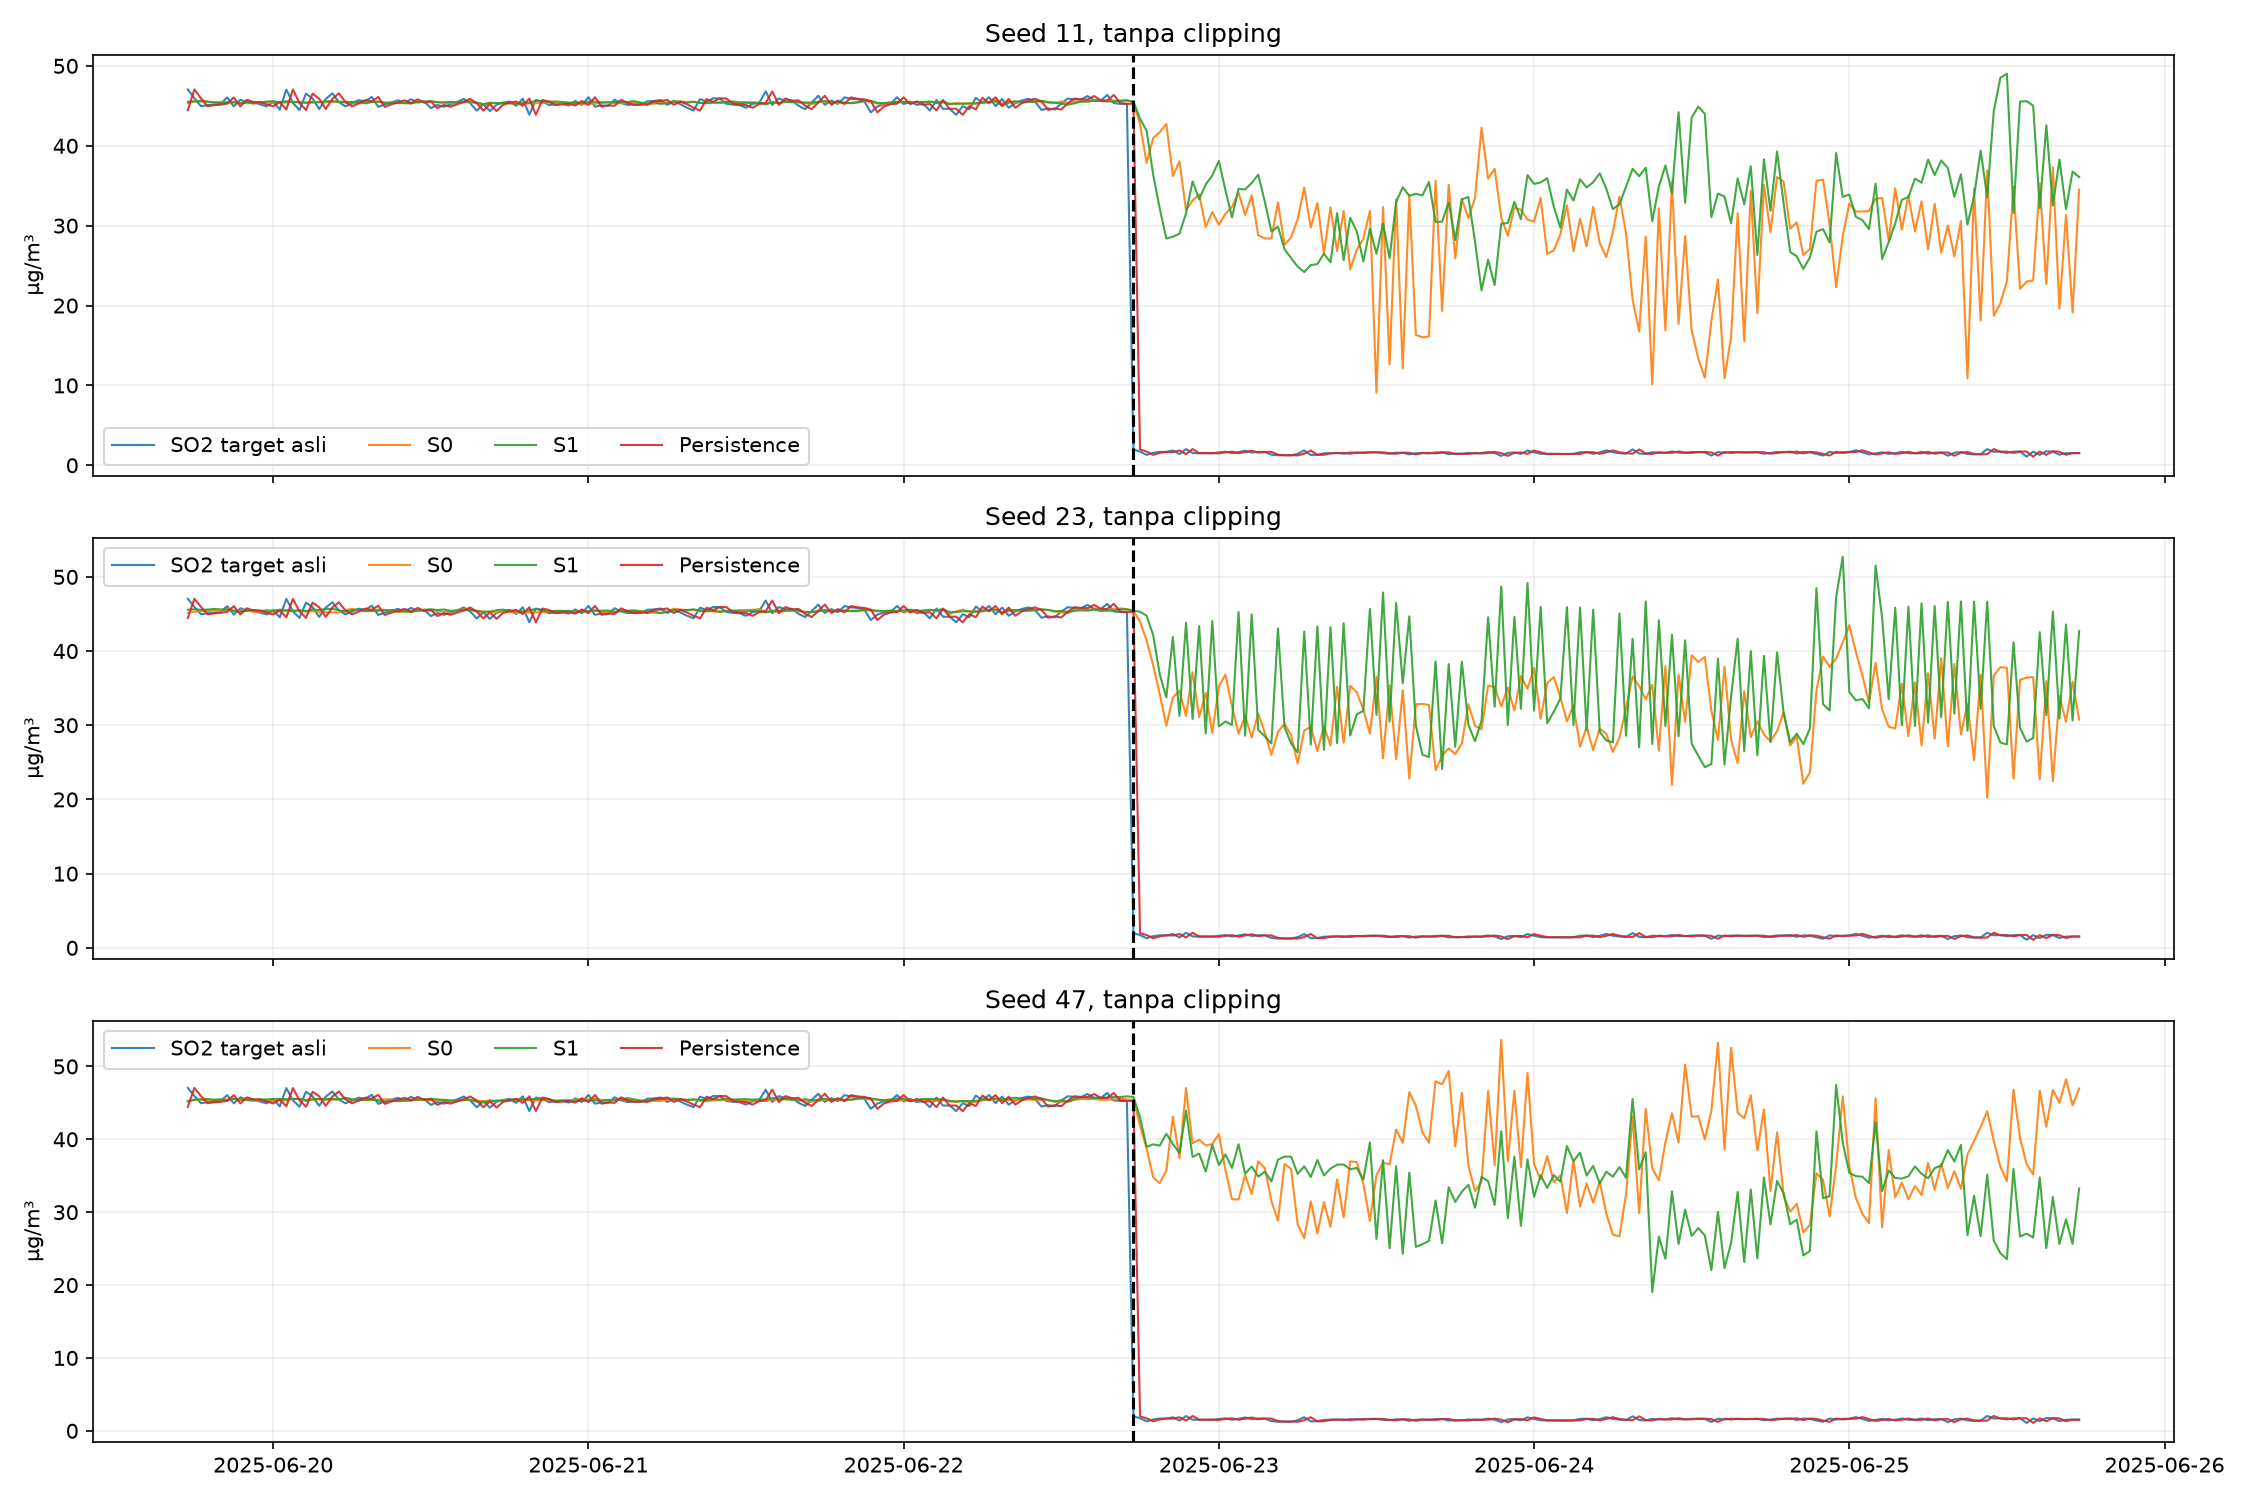

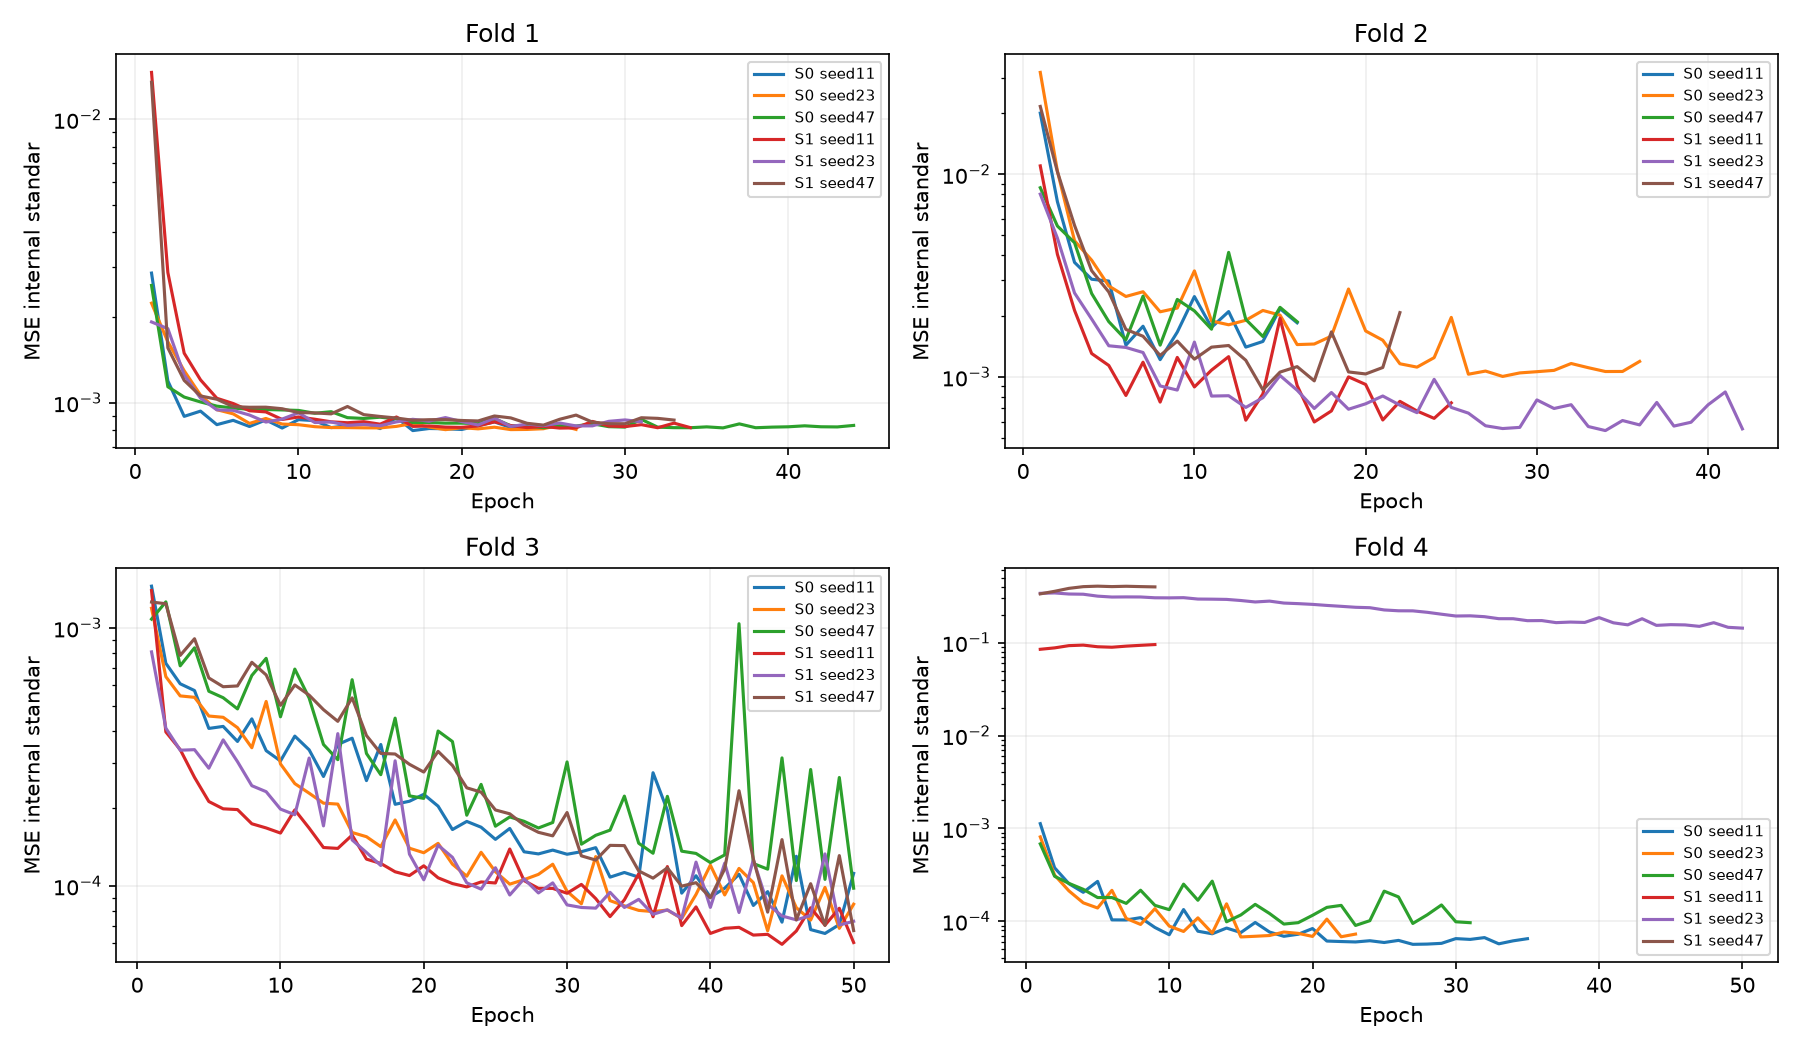

In [4]:
for name in ['Ketersediaan_donor','Ridge_timestamp_identik','Transisi_per_seed']:
    print(name);display(pd.DataFrame(t[name]))
for name in ['skor_per_fold.png','perubahan_pulomerak.png','transisi_22_juni.png','riwayat_early_stopping.png']:
    display(Image(filename=str(RUN/'figures'/name)))
verification=json.loads((RUN/'independent_checks.json').read_text())
print('Verifikasi tanpa training:',verification)


## Workbook dan interpretasi

Ekspor menggunakan Artifact Tool dari tabel hasil yang sudah diperiksa. CSV/NPZ mempertahankan timestamp seluruh bagian dan prediksi seluruh seed. File sumber dan artefak lama tidak ditimpa.

In [5]:
node=Path(r'C:\Program Files\WindowsApps\OpenAI.CodexPrimaryRuntime.v26-1104-2876-0_26.1104.2876.0_x64__3k8sg7r9htsxt\dependencies\node\bin\node.exe')
result=subprocess.run([str(node),str(ROOT/'scripts/export_quality.mjs'),'lstm_antarstasiun_tahap10/tabel_hasil.json','lstm_antarstasiun_tahap10/hasil_lstm_antarstasiun.xlsx','lstm_antarstasiun_tahap10/previews'],cwd=ROOT,capture_output=True,text=True,encoding='utf-8')
print(result.stdout)
if result.returncode:raise RuntimeError(result.stderr)
display(Markdown((RUN/'ringkasan_lstm_antarstasiun.md').read_text(encoding='utf-8')))


{"kind":"table","sheet":"Ringkasan","address":"A1:F4","rows":4,"cols":6,"values":[["Fold","Skenario","Domain","Seed N","MAE mean","MAE SD seed"],["Fold_01","S0","bersama",3,16.317958391502916,2.74457027234058],["Fold_01","S1","bersama",3,16.349923802761293,0.9890140732671211],["Fold_01","Persistence","bersama",3,0.43056237218813903,0]]}
Inspect result written to file: C:\Users\INTAN\airpollutan_SO2\outputs\lstm_antarstasiun_tahap10\hasil_lstm_antarstasiun.xlsx.inspect.ndjson
Ekspor selesai: 30 sheet.



# Tahap 10 — verifikasi kontribusi Pulomerak dengan LSTM

Eksperimen selesai dengan 24 model: empat fold kalender × S0/S1 × seed 11/23/47. Target seluruh model adalah SO₂ Way Urang asli pada 30 menit berikutnya. Development set telah digunakan dalam tahap sebelumnya, sehingga ini validasi pengembangan. Test akhir mulai 2026-06-19 06:30:00 tidak dimuat nilainya atau dievaluasi. Tidak memilih seed terbaik, mengubah split, menghapus fold pertama, atau melakukan tuning.

## Rancangan dan lingkungan

S0 memakai kanal dasar Way Urang tahap 7 tanpa Curah Hujan. S1 menambahkan hanya SO₂ Pulomerak lag1 dan indikator missing aslinya. Tidak memasukkan meteorologi Pulomerak atau Talang. Satu langkah sekuens mempunyai 11 kanal numerik + 11 indikator pada S0 dan 12 + 12 pada S1. Sekuens berisi 48 slot berurutan, dari origin−47 sampai origin, tanpa kompresi waktu atau duplikasi lag tabular.

| Skenario | Daftar kanal berurutan |
|---|---|
| S0 | SO2_origin, PM10_lag1, PM2.5_lag1, CO_lag1, O3_lag1, NO2_lag1, Kec.Angin_lag1, Kelembaban_lag1, Suhu_lag1, Tek.Udara_lag1, Sol.Rad_lag1, missing_asli_SO2_origin, missing_asli_PM10_lag1, missing_asli_PM2.5_lag1, missing_asli_CO_lag1, missing_asli_O3_lag1, missing_asli_NO2_lag1, missing_asli_Kec.Angin_lag1, missing_asli_Kelembaban_lag1, missing_asli_Suhu_lag1, missing_asli_Tek.Udara_lag1, missing_asli_Sol.Rad_lag1 |
| S1 | SO2_origin, PM10_lag1, PM2.5_lag1, CO_lag1, O3_lag1, NO2_lag1, Kec.Angin_lag1, Kelembaban_lag1, Suhu_lag1, Tek.Udara_lag1, Sol.Rad_lag1, Pulomerak_SO2_lag1, missing_asli_SO2_origin, missing_asli_PM10_lag1, missing_asli_PM2.5_lag1, missing_asli_CO_lag1, missing_asli_O3_lag1, missing_asli_NO2_lag1, missing_asli_Kec.Angin_lag1, missing_asli_Kelembaban_lag1, missing_asli_Suhu_lag1, missing_asli_Tek.Udara_lag1, missing_asli_Sol.Rad_lag1, missing_asli_Pulomerak_SO2_lag1 |

SO₂ Way Urang pada langkah u diasumsikan tersedia pada u. Sepuluh kovariat Way Urang memakai u−1. SO₂ Pulomerak pada setiap langkah u berasal dari u−1, sehingga slot donor terbaru dalam sekuens adalah origin−30 menit dan tertua origin−48 slot. Keterlambatan 30 menit merupakan asumsi eksperimen, bukan latensi operasional terverifikasi. Clock tertulis dianggap sebanding tanpa menebak zona waktu. Ketidakpastian sinkronisasi dan latensi membatasi interpretasi.

Model tetap: LSTM satu layer 32 unit, output linear satu unit, Adam learning rate 0,001, loss MSE target standar, batch 64, maksimal 50 epoch, early stopping patience 8 dan min_delta 0 pada validasi internal. Bobot terbaik internal dipulihkan. Tidak ada dropout, gradient clipping, clipping prediksi, backward fill, atau informasi masa depan. Jumlah parameter bertambah dari 7.201 pada S0 menjadi 7.457 pada S1 karena dua kanal tambahan. Seed sama tidak membuat bobot awal arsitektur dengan dimensi input berbeda identik. Urutan shuffle minibatch tetap sama antar-skenario untuk seed dan epoch yang sama.

Environment lama dipertahankan: `.venv-lstm`, Python 3.12.14, PyTorch 2.15.0+cpu, CPU, satu thread, deterministic algorithms aktif, GPU tidak digunakan. Versi lengkap dan perangkat ada pada konfigurasi dan `dependensi_freeze.txt`.

Percobaan persiapan pertama berhenti sebelum gate dan training karena modul pip tidak tersedia. Versi paket kemudian dicatat melalui importlib.metadata. Konfigurasi percobaan persiapan itu tetap disimpan sebagai `config_prefit_attempt_01.json`; rancangan dan parameter model tidak berubah. Konfigurasi operasional terkunci sebelum seluruh gate dan fit pada `config_locked.json`.

## Kalibrasi, scaling dan pembagian internal

Batas validasi internal adalah floor(0,85 × jumlah slot kalender train fold), bukan pembagian berdasarkan jumlah pengamatan. Sebanyak 15% bagian akhir kalender train digunakan untuk early stopping. Median kausal memakai warmup statistik 30 hari (1.440 slot), diperbarui tiap 30 hari dari raw prefix eksklusif awal query selama train internal, lalu dibekukan pada batas train internal untuk validasi internal dan evaluasi fold. Histori yang sudah diproses tidak dihitung ulang memakai statistik masa depan.

Kanal tertunda disusun sebelum imputasi. Untuk Pulomerak(u−1), prefix langkah [:start] hanya memuat timestamp sumber paling baru start−2. Karena itu median donor tidak menggunakan pengukuran yang belum tersedia pada origin. Ini mengikuti prosedur kanal sekuens tahap 7 dengan C30, bukan menggandakan fitur lag tabular tahap 9. Pengamatan asli baru yang sudah tersedia tetap menjadi input. Tanpa statistik median yang dapat diestimasi, fitur tetap kosong dan sekuens tidak layak; tidak menambah fallback. Target tidak pernah diimputasi atau diisi oleh stasiun lain.

Origin pertama tetap warmup+48=1.488 sesuai buffer sebelumnya. Jendela48 mencakup origin−47 sampai origin. Sampel train dengan target memasuki validasi internal dipurge. Sampel validasi internal berhenti sebelum target memasuki evaluasi fold. Konteks sebelumnya yang tersedia boleh masuk jendela validasi.

StandardScaler hanya di-fit pada slot langkah unik yang benar-benar masuk sekuens train internal bersama. Kanal numerik distandardisasi; indikator missing asli tetap 0/1. Mean dan SD populasi target dihitung hanya dari target asli train internal bersama, lalu prediksi di-inverse ke µg/m³ sebelum semua metrik. SD nol akan memakai 1 secara eksplisit; parameter yang digunakan tersimpan.

| Fold | Train internal akhir kalender | Validasi internal awal kalender | Validasi internal akhir kalender | Evaluasi awal kalender | Evaluasi akhir kalender | Train bersama | Validasi internal bersama | Evaluasi bersama | Fit count sebelum gate | Lulus |
|---|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | 2025-04-12 23:30:00 | 2025-04-13 00:00:00 | 2025-04-30 23:30:00 | 2025-05-01 00:00:00 | 2025-08-12 13:30:00 | 2679 | 860 | 4890 | 0 | True |
| Fold_02 | 2025-07-10 00:30:00 | 2025-07-10 01:00:00 | 2025-08-12 13:30:00 | 2025-08-12 14:00:00 | 2025-11-24 03:00:00 | 6822 | 1607 | 4969 | 0 | True |
| Fold_03 | 2025-10-06 01:00:00 | 2025-10-06 01:30:00 | 2025-11-24 03:00:00 | 2025-11-24 03:30:00 | 2026-03-07 16:30:00 | 11042 | 2356 | 4969 | 0 | True |
| Fold_04 | 2026-01-02 01:30:00 | 2026-01-02 02:00:00 | 2026-03-07 16:30:00 | 2026-03-07 17:00:00 | 2026-06-19 06:00:00 | 15267 | 3100 | 4969 | 0 | True |

## Jumlah sampel dan distribusi target

| Fold | Bagian | Skenario | Slot kalender target | Target asli seluruh bagian | Kandidat origin setelah warmup buffer purge | Target asli sebelum sekuens | Origin finite setelah imputasi | Sekuens lengkap 48 slot | Sesudah irisan | Keluar karena sekuens | Keluar karena irisan |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | inner_train | S0 | 4896 | 3064 | 3407 | 2679 | 2679 | 2679 | 2679 | 0 | 0 |
| Fold_01 | inner_train | S1 | 4896 | 3064 | 3407 | 2679 | 2679 | 2679 | 2679 | 0 | 0 |
| Fold_01 | inner_validation | S0 | 864 | 860 | 864 | 860 | 860 | 860 | 860 | 0 | 0 |
| Fold_01 | inner_validation | S1 | 864 | 860 | 864 | 860 | 860 | 860 | 860 | 0 | 0 |
| Fold_01 | evaluation | S0 | 4972 | 4890 | 4972 | 4890 | 4890 | 4890 | 4890 | 0 | 0 |
| Fold_01 | evaluation | S1 | 4972 | 4890 | 4972 | 4890 | 4890 | 4890 | 4890 | 0 | 0 |
| Fold_02 | inner_train | S0 | 9122 | 7207 | 7633 | 6822 | 6822 | 6822 | 6822 | 0 | 0 |
| Fold_02 | inner_train | S1 | 9122 | 7207 | 7633 | 6822 | 6822 | 6822 | 6822 | 0 | 0 |
| Fold_02 | inner_validation | S0 | 1610 | 1607 | 1610 | 1607 | 1607 | 1607 | 1607 | 0 | 0 |
| Fold_02 | inner_validation | S1 | 1610 | 1607 | 1610 | 1607 | 1607 | 1607 | 1607 | 0 | 0 |
| Fold_02 | evaluation | S0 | 4971 | 4969 | 4971 | 4969 | 4969 | 4969 | 4969 | 0 | 0 |
| Fold_02 | evaluation | S1 | 4971 | 4969 | 4971 | 4969 | 4969 | 4969 | 4969 | 0 | 0 |
| Fold_03 | inner_train | S0 | 13347 | 11427 | 11858 | 11042 | 11042 | 11042 | 11042 | 0 | 0 |
| Fold_03 | inner_train | S1 | 13347 | 11427 | 11858 | 11042 | 11042 | 11042 | 11042 | 0 | 0 |
| Fold_03 | inner_validation | S0 | 2356 | 2356 | 2356 | 2356 | 2356 | 2356 | 2356 | 0 | 0 |
| Fold_03 | inner_validation | S1 | 2356 | 2356 | 2356 | 2356 | 2356 | 2356 | 2356 | 0 | 0 |
| Fold_03 | evaluation | S0 | 4971 | 4969 | 4971 | 4969 | 4969 | 4969 | 4969 | 0 | 0 |
| Fold_03 | evaluation | S1 | 4971 | 4969 | 4971 | 4969 | 4969 | 4969 | 4969 | 0 | 0 |
| Fold_04 | inner_train | S0 | 17572 | 15652 | 16083 | 15267 | 15267 | 15267 | 15267 | 0 | 0 |
| Fold_04 | inner_train | S1 | 17572 | 15652 | 16083 | 15267 | 15267 | 15267 | 15267 | 0 | 0 |
| Fold_04 | inner_validation | S0 | 3102 | 3100 | 3102 | 3100 | 3100 | 3100 | 3100 | 0 | 0 |
| Fold_04 | inner_validation | S1 | 3102 | 3100 | 3102 | 3100 | 3100 | 3100 | 3100 | 0 | 0 |
| Fold_04 | evaluation | S0 | 4971 | 4969 | 4971 | 4969 | 4969 | 4969 | 4969 | 0 | 0 |
| Fold_04 | evaluation | S1 | 4971 | 4969 | 4971 | 4969 | 4969 | 4969 | 4969 | 0 | 0 |

“Target asli sebelum sekuens” memakai kandidat setelah warmup, buffer dan purge. Kelengkapan satu origin setelah imputasi tidak menjamin seluruh 48 langkah lengkap. Ledger setiap timestamp menyimpan alasan yang dapat tumpang tindih: target kosong, input origin masih kosong, sekuens tidak lengkap, serta hasil irisan. Jumlah per tahap bukan penjumlahan alasan yang tumpang tindih. Tidak menghapus slot dari grid untuk merapatkan sekuens.

| Fold | Bagian | Skenario | N | Minimum | Median | Maksimum |
|---|---|---|---|---|---|---|
| Fold_01 | inner_train | S0 | 0 | — | — | — |
| Fold_01 | inner_train | S1 | 0 | — | — | — |
| Fold_01 | inner_validation | S0 | 0 | — | — | — |
| Fold_01 | inner_validation | S1 | 0 | — | — | — |
| Fold_01 | evaluation | S0 | 0 | — | — | — |
| Fold_01 | evaluation | S1 | 0 | — | — | — |
| Fold_02 | inner_train | S0 | 0 | — | — | — |
| Fold_02 | inner_train | S1 | 0 | — | — | — |
| Fold_02 | inner_validation | S0 | 0 | — | — | — |
| Fold_02 | inner_validation | S1 | 0 | — | — | — |
| Fold_02 | evaluation | S0 | 0 | — | — | — |
| Fold_02 | evaluation | S1 | 0 | — | — | — |
| Fold_03 | inner_train | S0 | 0 | — | — | — |
| Fold_03 | inner_train | S1 | 0 | — | — | — |
| Fold_03 | inner_validation | S0 | 0 | — | — | — |
| Fold_03 | inner_validation | S1 | 0 | — | — | — |
| Fold_03 | evaluation | S0 | 0 | — | — | — |
| Fold_03 | evaluation | S1 | 0 | — | — | — |
| Fold_04 | inner_train | S0 | 0 | — | — | — |
| Fold_04 | inner_train | S1 | 0 | — | — | — |
| Fold_04 | inner_validation | S0 | 0 | — | — | — |
| Fold_04 | inner_validation | S1 | 0 | — | — | — |
| Fold_04 | evaluation | S0 | 0 | — | — | — |
| Fold_04 | evaluation | S1 | 0 | — | — | — |

| Fold | Bagian | Alasan | Slot tersisih | N | Minimum | Median | Maksimum |
|---|---|---|---|---|---|---|---|
| Fold_01 | inner_train | target kosong | 1832 | 0 | — | — | — |
| Fold_01 | inner_train | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_01 | inner_train | warmup statistik | 385 | 385 | 0.92 | 1.63 | 2.15 |
| Fold_01 | inner_train | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_01 | inner_train | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_01 | inner_validation | target kosong | 4 | 0 | — | — | — |
| Fold_01 | inner_validation | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_01 | inner_validation | warmup statistik | 0 | 0 | — | — | — |
| Fold_01 | inner_validation | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_01 | inner_validation | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_01 | evaluation | target kosong | 82 | 0 | — | — | — |
| Fold_01 | evaluation | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_01 | evaluation | warmup statistik | 0 | 0 | — | — | — |
| Fold_01 | evaluation | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_01 | evaluation | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_02 | inner_train | target kosong | 1915 | 0 | — | — | — |
| Fold_02 | inner_train | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_02 | inner_train | warmup statistik | 385 | 385 | 0.92 | 1.63 | 2.15 |
| Fold_02 | inner_train | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_02 | inner_train | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_02 | inner_validation | target kosong | 3 | 0 | — | — | — |
| Fold_02 | inner_validation | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_02 | inner_validation | warmup statistik | 0 | 0 | — | — | — |
| Fold_02 | inner_validation | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_02 | inner_validation | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_02 | evaluation | target kosong | 2 | 0 | — | — | — |
| Fold_02 | evaluation | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_02 | evaluation | warmup statistik | 0 | 0 | — | — | — |
| Fold_02 | evaluation | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_02 | evaluation | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_03 | inner_train | target kosong | 1920 | 0 | — | — | — |
| Fold_03 | inner_train | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_03 | inner_train | warmup statistik | 385 | 385 | 0.92 | 1.63 | 2.15 |
| Fold_03 | inner_train | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_03 | inner_train | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_03 | inner_validation | target kosong | 0 | 0 | — | — | — |
| Fold_03 | inner_validation | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_03 | inner_validation | warmup statistik | 0 | 0 | — | — | — |
| Fold_03 | inner_validation | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_03 | inner_validation | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_03 | evaluation | target kosong | 2 | 0 | — | — | — |
| Fold_03 | evaluation | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_03 | evaluation | warmup statistik | 0 | 0 | — | — | — |
| Fold_03 | evaluation | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_03 | evaluation | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_04 | inner_train | target kosong | 1920 | 0 | — | — | — |
| Fold_04 | inner_train | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_04 | inner_train | warmup statistik | 385 | 385 | 0.92 | 1.63 | 2.15 |
| Fold_04 | inner_train | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_04 | inner_train | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_04 | inner_validation | target kosong | 2 | 0 | — | — | — |
| Fold_04 | inner_validation | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_04 | inner_validation | warmup statistik | 0 | 0 | — | — | — |
| Fold_04 | inner_validation | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_04 | inner_validation | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |
| Fold_04 | evaluation | target kosong | 2 | 0 | — | — | — |
| Fold_04 | evaluation | histori sebelum grid | 0 | 0 | — | — | — |
| Fold_04 | evaluation | warmup statistik | 0 | 0 | — | — | — |
| Fold_04 | evaluation | buffer setelah warmup | 0 | 0 | — | — | — |
| Fold_04 | evaluation | sesudah warmup tetapi tidak masuk irisan | 0 | 0 | — | — | — |

Tabel sampel tersisih membedakan target kosong (N numerik=0), histori sebelum grid, warmup, buffer, dan sampel sesudah warmup yang tidak masuk irisan. Distribusi bulanan dan timestamp batas purge tersedia di workbook. Sampel yang targetnya melintasi batas dilarang masuk bagian sebelumnya, tetapi tetap dapat dievaluasi pada bagian sesudahnya. Dengan demikian purge bukan penghapusan label global.

| Fold | Bagian | Domain | Target awal | Target akhir | N | Minimum | P25 | Median | P75 | Maksimum | Mean | SD |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | inner_train | bersama digunakan | 2025-02-13 19:00:00 | 2025-04-12 23:30:00 | 2679 | 1.24 | 1.45 | 45.15 | 45.80 | 80.71 | 36.23 | 22.40 |
| Fold_01 | inner_validation | bersama digunakan | 2025-04-13 00:00:00 | 2025-04-30 23:30:00 | 860 | 43.72 | 45.02 | 45.45 | 45.84 | 47.29 | 45.44 | 0.62 |
| Fold_01 | evaluation | bersama digunakan | 2025-05-01 00:00:00 | 2025-08-12 13:30:00 | 4890 | 1.07 | 1.56 | 43.85 | 45.38 | 47.81 | 23.58 | 21.93 |
| Fold_02 | inner_train | bersama digunakan | 2025-02-13 19:00:00 | 2025-07-10 00:30:00 | 6822 | 1.07 | 44.24 | 45.18 | 45.74 | 80.71 | 36.49 | 19.59 |
| Fold_02 | inner_validation | bersama digunakan | 2025-07-10 01:00:00 | 2025-08-12 13:30:00 | 1607 | 1.08 | 1.49 | 1.56 | 1.63 | 2.10 | 1.56 | 0.12 |
| Fold_02 | evaluation | bersama digunakan | 2025-08-12 14:00:00 | 2025-11-24 03:00:00 | 4969 | 1.04 | 1.48 | 1.56 | 1.64 | 2.14 | 1.56 | 0.13 |
| Fold_03 | inner_train | bersama digunakan | 2025-02-13 19:00:00 | 2025-10-06 01:00:00 | 11042 | 1.04 | 1.54 | 1.76 | 45.39 | 80.71 | 23.14 | 22.92 |
| Fold_03 | inner_validation | bersama digunakan | 2025-10-06 01:30:00 | 2025-11-24 03:00:00 | 2356 | 1.04 | 1.47 | 1.56 | 1.65 | 2.07 | 1.56 | 0.14 |
| Fold_03 | evaluation | bersama digunakan | 2025-11-24 03:30:00 | 2026-03-07 16:30:00 | 4969 | 1.08 | 1.49 | 1.56 | 1.63 | 2.04 | 1.56 | 0.13 |
| Fold_04 | inner_train | bersama digunakan | 2025-02-13 19:00:00 | 2026-01-02 01:30:00 | 15267 | 1.04 | 1.52 | 1.64 | 45.05 | 80.71 | 17.17 | 21.75 |
| Fold_04 | inner_validation | bersama digunakan | 2026-01-02 02:00:00 | 2026-03-07 16:30:00 | 3100 | 1.08 | 1.49 | 1.56 | 1.63 | 2.04 | 1.56 | 0.12 |
| Fold_04 | evaluation | bersama digunakan | 2026-03-07 17:00:00 | 2026-06-19 06:00:00 | 4969 | 1.09 | 1.49 | 1.56 | 1.63 | 2.06 | 1.56 | 0.11 |

Distribusi sebelum/sesudah pembentukan sekuens dan perbulan ada dalam workbook. Median C30 adalah pilihan operasional sementara, bukan metode yang telah terbukti paling akurat. Kecukupan komputasional minimal 64 sampel tidak menjamin keterwakilan distribusi.

Kolom hitungan SO₂>2,14 pada tabel distribusi hanya penelusuran konsentrasi yang digunakan pada tahap terdahulu, bukan ambang kualitas, bahaya, atau aturan seleksi.

Pada fold pertama, target train internal mencakup 1,24–80,71 µg/m³, tetapi validasi internal hanya 43,72–47,29 µg/m³. Dengan demikian early stopping memantau periode berkonsentrasi tinggi yang sempit, sedangkan evaluasi melintasi penurunan ke tingkat rendah. Pemeriksaan ini menunjukkan keterbatasan keterwakilan validasi internal, bukan bukti penyebab tunggal kegagalan atau alasan untuk mengganti split. Pada fold 2–4, jendela evaluasi jauh lebih rendah dan sempit, sekitar 1,04–2,14 µg/m³.

## Hasil per fold dan seed pada timestamp identik

| Fold | Seed | Skenario | N | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | 11 | S0 | 4890 | 100.000 | 14.088429 | 20.431628 | 13.834207 | 0 |
| Fold_01 | 11 | S1 | 4890 | 100.000 | 16.103345 | 22.777251 | 15.855943 | 0 |
| Fold_01 | 11 | Persistence | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_01 | 23 | S0 | 4890 | 100.000 | 15.482194 | 21.866398 | 15.211474 | 0 |
| Fold_01 | 23 | S1 | 4890 | 100.000 | 17.438899 | 24.967605 | 17.173076 | 0 |
| Fold_01 | 23 | Persistence | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_01 | 47 | S0 | 4890 | 100.000 | 19.383252 | 27.573651 | 19.127404 | 0 |
| Fold_01 | 47 | S1 | 4890 | 100.000 | 15.507528 | 21.932423 | 15.268016 | 0 |
| Fold_01 | 47 | Persistence | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_02 | 11 | S0 | 4969 | 100.000 | 0.734822 | 1.073573 | 0.377596 | 22 |
| Fold_02 | 11 | S1 | 4969 | 100.000 | 0.510898 | 0.691437 | 0.030137 | 21 |
| Fold_02 | 11 | Persistence | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_02 | 23 | S0 | 4969 | 100.000 | 1.152306 | 1.490542 | 0.971297 | 55 |
| Fold_02 | 23 | S1 | 4969 | 100.000 | 0.365721 | 0.483383 | -0.096298 | 6 |
| Fold_02 | 23 | Persistence | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_02 | 47 | S0 | 4969 | 100.000 | 0.696230 | 0.911808 | 0.229197 | 90 |
| Fold_02 | 47 | S1 | 4969 | 100.000 | 0.511799 | 0.776936 | 0.081944 | 38 |
| Fold_02 | 47 | Persistence | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_03 | 11 | S0 | 4969 | 100.000 | 0.121554 | 0.167534 | -0.018705 | 2 |
| Fold_03 | 11 | S1 | 4969 | 100.000 | 4.064909 | 10.857817 | 3.984418 | 0 |
| Fold_03 | 11 | Persistence | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_03 | 23 | S0 | 4969 | 100.000 | 0.125210 | 0.192803 | -0.011169 | 2 |
| Fold_03 | 23 | S1 | 4969 | 100.000 | 3.478770 | 9.604572 | 3.191693 | 4 |
| Fold_03 | 23 | Persistence | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_03 | 47 | S0 | 4969 | 100.000 | 0.134902 | 0.229740 | 0.019808 | 5 |
| Fold_03 | 47 | S1 | 4969 | 100.000 | 3.359977 | 9.458665 | 3.276156 | 4 |
| Fold_03 | 47 | Persistence | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_04 | 11 | S0 | 4969 | 100.000 | 0.112114 | 0.167962 | 0.017715 | 2 |
| Fold_04 | 11 | S1 | 4969 | 100.000 | 12.269951 | 14.137783 | 12.191257 | 0 |
| Fold_04 | 11 | Persistence | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |
| Fold_04 | 23 | S0 | 4969 | 100.000 | 0.145639 | 0.270735 | -0.005944 | 3 |
| Fold_04 | 23 | S1 | 4969 | 100.000 | 15.845153 | 18.338920 | 15.732156 | 1 |
| Fold_04 | 23 | Persistence | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |
| Fold_04 | 47 | S0 | 4969 | 100.000 | 0.157629 | 0.263519 | 0.079551 | 10 |
| Fold_04 | 47 | S1 | 4969 | 100.000 | 23.968101 | 27.139646 | 23.968101 | 0 |
| Fold_04 | 47 | Persistence | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |

Error e=prediksi−target asli. MAE=mean(|e|), RMSE=sqrt(mean(e²)), bias=mean(e), seluruhnya dalam µg/m³. Cakupan(%)=100×N prediksi finite / seluruh target Way Urang asli numerik teramati dalam jendela tersebut. Cakupan bersama memakai irisan S0/S1/persistence. Target kosong tidak diberi nilai untuk penilaian. Pengamatan numerik teramati tidak otomatis dinyatakan valid berdasarkan dokumentasi sensor.

Hasil mandiri dan cakupan terhadap denominator seluruh target asli:

| Fold | Seed | Skenario | N | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | 11 | S0 | 4890 | 100.000 | 14.088429 | 20.431628 | 13.834207 | 0 |
| Fold_01 | 11 | S1 | 4890 | 100.000 | 16.103345 | 22.777251 | 15.855943 | 0 |
| Fold_01 | 11 | Persistence | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_01 | 23 | S0 | 4890 | 100.000 | 15.482194 | 21.866398 | 15.211474 | 0 |
| Fold_01 | 23 | S1 | 4890 | 100.000 | 17.438899 | 24.967605 | 17.173076 | 0 |
| Fold_01 | 23 | Persistence | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_01 | 47 | S0 | 4890 | 100.000 | 19.383252 | 27.573651 | 19.127404 | 0 |
| Fold_01 | 47 | S1 | 4890 | 100.000 | 15.507528 | 21.932423 | 15.268016 | 0 |
| Fold_01 | 47 | Persistence | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_02 | 11 | S0 | 4969 | 100.000 | 0.734822 | 1.073573 | 0.377596 | 22 |
| Fold_02 | 11 | S1 | 4969 | 100.000 | 0.510898 | 0.691437 | 0.030137 | 21 |
| Fold_02 | 11 | Persistence | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_02 | 23 | S0 | 4969 | 100.000 | 1.152306 | 1.490542 | 0.971297 | 55 |
| Fold_02 | 23 | S1 | 4969 | 100.000 | 0.365721 | 0.483383 | -0.096298 | 6 |
| Fold_02 | 23 | Persistence | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_02 | 47 | S0 | 4969 | 100.000 | 0.696230 | 0.911808 | 0.229197 | 90 |
| Fold_02 | 47 | S1 | 4969 | 100.000 | 0.511799 | 0.776936 | 0.081944 | 38 |
| Fold_02 | 47 | Persistence | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_03 | 11 | S0 | 4969 | 100.000 | 0.121554 | 0.167534 | -0.018705 | 2 |
| Fold_03 | 11 | S1 | 4969 | 100.000 | 4.064909 | 10.857817 | 3.984418 | 0 |
| Fold_03 | 11 | Persistence | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_03 | 23 | S0 | 4969 | 100.000 | 0.125210 | 0.192803 | -0.011169 | 2 |
| Fold_03 | 23 | S1 | 4969 | 100.000 | 3.478770 | 9.604572 | 3.191693 | 4 |
| Fold_03 | 23 | Persistence | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_03 | 47 | S0 | 4969 | 100.000 | 0.134902 | 0.229740 | 0.019808 | 5 |
| Fold_03 | 47 | S1 | 4969 | 100.000 | 3.359977 | 9.458665 | 3.276156 | 4 |
| Fold_03 | 47 | Persistence | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_04 | 11 | S0 | 4969 | 100.000 | 0.112114 | 0.167962 | 0.017715 | 2 |
| Fold_04 | 11 | S1 | 4969 | 100.000 | 12.269951 | 14.137783 | 12.191257 | 0 |
| Fold_04 | 11 | Persistence | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |
| Fold_04 | 23 | S0 | 4969 | 100.000 | 0.145639 | 0.270735 | -0.005944 | 3 |
| Fold_04 | 23 | S1 | 4969 | 100.000 | 15.845153 | 18.338920 | 15.732156 | 1 |
| Fold_04 | 23 | Persistence | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |
| Fold_04 | 47 | S0 | 4969 | 100.000 | 0.157629 | 0.263519 | 0.079551 | 10 |
| Fold_04 | 47 | S1 | 4969 | 100.000 | 23.968101 | 27.139646 | 23.968101 | 0 |
| Fold_04 | 47 | Persistence | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |

Persistence menggunakan SO₂ Way Urang asli terakhir pada/sebelum origin, tanpa imputasi dan tanpa batas usia. Usia donor persistence disimpan per prediksi. Persistence identik untuk ketiga seed dan bukan tiga replikasi stokastik independen.

| Fold | Skenario | MAE mean | MAE SD seed | RMSE mean | RMSE SD seed | Bias mean | Cakupan persen mean | Prediksi negatif mean |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | S0 | 16.317958 | 2.744570 | 23.290559 | 3.778002 | 16.057695 | 100.000 | 0.00 |
| Fold_01 | S1 | 16.349924 | 0.989014 | 23.225760 | 1.566510 | 16.099012 | 100.000 | 0.00 |
| Fold_01 | Persistence | 0.430562 | 0.000000 | 0.885256 | 0.000000 | 0.009049 | 100.000 | 0.00 |
| Fold_02 | S0 | 0.861119 | 0.252912 | 1.158641 | 0.298598 | 0.526030 | 100.000 | 55.67 |
| Fold_02 | S1 | 0.462806 | 0.084079 | 0.650585 | 0.150980 | 0.005261 | 100.000 | 21.67 |
| Fold_02 | Persistence | 0.142954 | 0.000000 | 0.183682 | 0.000000 | -0.000020 | 100.000 | 0.00 |
| Fold_03 | S0 | 0.127222 | 0.006898 | 0.196692 | 0.031285 | -0.003355 | 100.000 | 3.00 |
| Fold_03 | S1 | 3.634552 | 0.377403 | 9.973685 | 0.769149 | 3.484089 | 100.000 | 2.67 |
| Fold_03 | Persistence | 0.139453 | 0.000000 | 0.178418 | 0.000000 | 0.000016 | 100.000 | 0.00 |
| Fold_04 | S0 | 0.138461 | 0.023591 | 0.234072 | 0.057367 | 0.030441 | 100.000 | 5.00 |
| Fold_04 | S1 | 17.361068 | 5.994596 | 19.872116 | 6.635143 | 17.297171 | 100.000 | 0.33 |
| Fold_04 | Persistence | 0.115935 | 0.000000 | 0.149092 | 0.000000 | 0.000024 | 100.000 | 0.00 |

SD antar-seed adalah SD sampel ddof1 dari tiga seed, bukan interval keyakinan atau uji signifikansi. Perbandingan utama mempertahankan semua seed.

| Fold | Seed | N identik | Perbaikan MAE persen | Perbaikan RMSE persen | Delta MAE S1 minus S0 | Delta RMSE S1 minus S0 | Delta MAE S0 minus persistence | Delta MAE S1 minus persistence | Delta RMSE S0 minus persistence | Delta RMSE S1 minus persistence |
|---|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | 11 | 4890 | -14.301920 | -11.480352 | 2.014916 | 2.345623 | 13.657867 | 15.672782 | 19.546372 | 21.891995 |
| Fold_01 | 23 | 4890 | -12.638420 | -14.182521 | 1.956705 | 3.101207 | 15.051631 | 17.008336 | 20.981143 | 24.082349 |
| Fold_01 | 47 | 4890 | 19.995222 | 20.458764 | -3.875724 | -5.641228 | 18.952690 | 15.076966 | 26.688395 | 21.047167 |
| Fold_02 | 11 | 4969 | 30.473265 | 35.594793 | -0.223924 | -0.382136 | 0.591868 | 0.367944 | 0.889892 | 0.507755 |
| Fold_02 | 23 | 4969 | 68.261832 | 67.569968 | -0.786585 | -1.007159 | 1.009352 | 0.222767 | 1.306861 | 0.299702 |
| Fold_02 | 47 | 4969 | 26.489972 | 14.791765 | -0.184431 | -0.134873 | 0.553276 | 0.368844 | 0.728127 | 0.593254 |
| Fold_03 | 11 | 4969 | -3244.120532 | -6380.975218 | 3.943355 | 10.690283 | -0.017899 | 3.925457 | -0.010884 | 10.679399 |
| Fold_03 | 23 | 4969 | -2678.353931 | -4881.558531 | 3.353561 | 9.411770 | -0.014243 | 3.339318 | 0.014385 | 9.426155 |
| Fold_03 | 47 | 4969 | -2390.682305 | -4017.114924 | 3.225075 | 9.228925 | -0.004551 | 3.220525 | 0.051322 | 9.280247 |
| Fold_04 | 11 | 4969 | -10844.160186 | -8317.257782 | 12.157837 | 13.969821 | -0.003821 | 12.154016 | 0.018870 | 13.988691 |
| Fold_04 | 23 | 4969 | -10779.761124 | -6673.755422 | 15.699514 | 18.068185 | 0.029704 | 15.729218 | 0.121643 | 18.189828 |
| Fold_04 | 47 | 4969 | -15105.413837 | -10198.923367 | 23.810472 | 26.876127 | 0.041694 | 23.852166 | 0.114427 | 26.990554 |
| Gabungan_OOF | 11 | 19797 | -120.408748 | -41.828821 | 4.482855 | 4.253744 | 3.516696 | 7.999551 | 9.705070 | 13.958814 |
| Gabungan_OOF | 23 | 19797 | -121.206786 | -48.463219 | 5.068165 | 5.279805 | 3.975086 | 9.043251 | 10.430117 | 15.709922 |
| Gabungan_OOF | 47 | 19797 | -114.818513 | -31.729545 | 5.782235 | 4.351004 | 4.829643 | 10.611878 | 13.248443 | 17.599446 |

Perbaikan (%)=100×(error S0−error S1)/error S0, sehingga positif berarti S1 lebih baik. Delta adalah error skenario dikurangi baseline, sehingga negatif berarti error lebih rendah. Bias dinilai kedekatannya dengan nol, bukan hanya tandanya.

## Gabungan dan kestabilan antarperiode

| Fold | Seed | Skenario | N | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|---|
| Gabungan_OOF | 11 | S0 | 19797 | 100.000 | 3.723031 | 10.169410 | 3.511675 | 26 |
| Gabungan_OOF | 11 | S1 | 19797 | 100.000 | 8.205886 | 14.423154 | 7.984151 | 21 |
| Gabungan_OOF | 11 | Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 | 0 |
| Gabungan_OOF | 23 | S0 | 19797 | 100.000 | 4.181421 | 10.894457 | 3.996841 | 60 |
| Gabungan_OOF | 23 | S1 | 19797 | 100.000 | 9.249586 | 16.174262 | 8.967543 | 11 |
| Gabungan_OOF | 23 | Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 | 0 |
| Gabungan_OOF | 47 | S0 | 19797 | 100.000 | 5.035978 | 13.712783 | 4.807072 | 105 |
| Gabungan_OOF | 47 | S1 | 19797 | 100.000 | 10.818213 | 18.063786 | 10.630120 | 42 |
| Gabungan_OOF | 47 | Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 | 0 |

Metrik gabungan dihitung ulang dari error seluruh fold evaluasi yang tidak tumpang tindih, terpisah untuk setiap seed. RMSE gabungan bukan rata-rata RMSE fold.

| Skenario | MAE mean | MAE SD seed | RMSE mean | RMSE SD seed | Bias mean | Cakupan persen mean |
|---|---|---|---|---|---|---|
| S0 | 4.313477 | 0.666361 | 11.592217 | 1.871904 | 4.105196 | 100.000 |
| S1 | 9.424562 | 1.314924 | 16.220401 | 1.820755 | 9.193938 | 100.000 |
| Persistence | 0.206335 | 0.000000 | 0.464340 | 0.000000 | 0.002240 | 100.000 |

| Fold | Seed MAE dan RMSE membaik | Seed keduanya memburuk | Seed hasil campuran | Perbaikan MAE min persen | Perbaikan MAE max persen | Perbaikan RMSE min persen | Perbaikan RMSE max persen |
|---|---|---|---|---|---|---|---|
| Fold_01 | 1 | 2 | 0 | -14.301920 | 19.995222 | -14.182521 | 20.458764 |
| Fold_02 | 3 | 0 | 0 | 26.489972 | 68.261832 | 14.791765 | 67.569968 |
| Fold_03 | 0 | 3 | 0 | -3244.120532 | -2390.682305 | -6380.975218 | -4017.114924 |
| Fold_04 | 0 | 3 | 0 | -15105.413837 | -10779.761124 | -10198.923367 | -6673.755422 |

Pulomerak memperbaiki MAE dan RMSE sekaligus pada 4/12 pasangan fold–seed dan memperburuk keduanya pada 8/12. Hasil lainnya campuran. Selisih ini deskriptif; fold expanding berbagi histori dan tiga seed tidak membuktikan signifikansi statistik. Skor dan persentase perubahan perbulan disimpan terpisah menurut fold dan seed agar periode yang berbeda tidak tersamarkan oleh gabungan.

![Skor](figures/skor_per_fold.png)

![Perubahan](figures/perubahan_pulomerak.png)

## Transisi konsentrasi 22 Juni 2025

Pusat transisi 2025-06-22 17:30 dan jendela ±72 jam mengikuti diagnosis terdahulu, bukan dipilih dari skor LSTM tahap 10. Fold pertama, prediksi negatif dan semua seed dipertahankan tanpa clipping. Tabel berikut memisahkan sebelum dan sesudah pusat transisi dengan timestamp yang sama.

| Seed | Periode | Skenario | N | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|
| 11 | sebelum transisi | S0 | 144 | 0.442596 | 0.569922 | 0.049806 | 0 |
| 11 | sebelum transisi | S1 | 144 | 0.448173 | 0.571850 | 0.075289 | 0 |
| 11 | sebelum transisi | Persistence | 144 | 0.602500 | 0.783946 | -0.005556 | 0 |
| 11 | sesudah transisi | S0 | 145 | 27.132007 | 28.113190 | 27.132007 | 0 |
| 11 | sesudah transisi | S1 | 145 | 31.834771 | 32.279348 | 31.834771 | 0 |
| 11 | sesudah transisi | Persistence | 145 | 0.465034 | 3.600567 | 0.301586 | 0 |
| 23 | sebelum transisi | S0 | 144 | 0.465829 | 0.586869 | 0.039263 | 0 |
| 23 | sebelum transisi | S1 | 144 | 0.446582 | 0.577007 | 0.080649 | 0 |
| 23 | sebelum transisi | Persistence | 144 | 0.602500 | 0.783946 | -0.005556 | 0 |
| 23 | sesudah transisi | S0 | 145 | 30.509249 | 30.912249 | 30.509249 | 0 |
| 23 | sesudah transisi | S1 | 145 | 34.067356 | 34.938748 | 34.067356 | 0 |
| 23 | sesudah transisi | Persistence | 145 | 0.465034 | 3.600567 | 0.301586 | 0 |
| 47 | sebelum transisi | S0 | 144 | 0.439979 | 0.567788 | 0.012655 | 0 |
| 47 | sebelum transisi | S1 | 144 | 0.442374 | 0.567577 | 0.087216 | 0 |
| 47 | sebelum transisi | Persistence | 144 | 0.602500 | 0.783946 | -0.005556 | 0 |
| 47 | sesudah transisi | S0 | 145 | 36.037883 | 36.571058 | 36.037883 | 0 |
| 47 | sesudah transisi | S1 | 145 | 31.821195 | 32.279924 | 31.821195 | 0 |
| 47 | sesudah transisi | Persistence | 145 | 0.465034 | 3.600567 | 0.301586 | 0 |

| Seed | Periode | Skenario | N | Target mean | Target median | Prediksi mean | Prediksi median | Prediksi minimum | Prediksi maksimum |
|---|---|---|---|---|---|---|---|---|---|
| 11 | sebelum transisi | S0 | 144 | 45.36 | 45.34 | 45.41 | 45.41 | 45.18 | 45.70 |
| 11 | sebelum transisi | S1 | 144 | 45.36 | 45.34 | 45.44 | 45.45 | 45.02 | 45.68 |
| 11 | sebelum transisi | Persistence | 144 | 45.36 | 45.34 | 45.36 | 45.34 | 43.87 | 47.05 |
| 11 | sesudah transisi | S0 | 145 | 1.56 | 1.56 | 28.69 | 30.41 | 9.09 | 45.42 |
| 11 | sesudah transisi | S1 | 145 | 1.56 | 1.56 | 33.39 | 33.33 | 21.89 | 49.03 |
| 11 | sesudah transisi | Persistence | 145 | 1.56 | 1.56 | 1.86 | 1.56 | 1.08 | 45.25 |
| 23 | sebelum transisi | S0 | 144 | 45.36 | 45.34 | 45.40 | 45.40 | 44.96 | 45.75 |
| 23 | sebelum transisi | S1 | 144 | 45.36 | 45.34 | 45.45 | 45.44 | 45.09 | 45.69 |
| 23 | sebelum transisi | Persistence | 144 | 45.36 | 45.34 | 45.36 | 45.34 | 43.87 | 47.05 |
| 23 | sesudah transisi | S0 | 145 | 1.56 | 1.56 | 32.07 | 32.10 | 20.27 | 45.46 |
| 23 | sesudah transisi | S1 | 145 | 1.56 | 1.56 | 35.63 | 32.22 | 24.09 | 52.71 |
| 23 | sesudah transisi | Persistence | 145 | 1.56 | 1.56 | 1.86 | 1.56 | 1.08 | 45.25 |
| 47 | sebelum transisi | S0 | 144 | 45.36 | 45.34 | 45.38 | 45.39 | 45.11 | 45.70 |
| 47 | sebelum transisi | S1 | 144 | 45.36 | 45.34 | 45.45 | 45.47 | 45.09 | 45.90 |
| 47 | sebelum transisi | Persistence | 144 | 45.36 | 45.34 | 45.36 | 45.34 | 43.87 | 47.05 |
| 47 | sesudah transisi | S0 | 145 | 1.56 | 1.56 | 37.60 | 36.60 | 26.43 | 53.64 |
| 47 | sesudah transisi | S1 | 145 | 1.56 | 1.56 | 33.38 | 34.82 | 19.04 | 47.46 |
| 47 | sesudah transisi | Persistence | 145 | 1.56 | 1.56 | 1.86 | 1.56 | 1.08 | 45.25 |

![Transisi](figures/transisi_22_juni.png)

## Ketersediaan informasi donor dan kualitas

| Fold | Bagian | N sekuens bersama | Posisi fitur donor | Posisi donor missing asli diimputasi | Proporsi posisi donor diimputasi persen | Sekuens dengan donor diimputasi persen | Usia donor origin median menit | Usia donor origin P95 menit | Usia donor origin maksimum menit |
|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | inner_train | 2679 | 128592 | 23320 | 18.135 | 22.695 | 30.00 | 6783.00 | 10800.00 |
| Fold_01 | inner_validation | 860 | 41280 | 10200 | 24.709 | 38.372 | 30.00 | 15151.50 | 16440.00 |
| Fold_01 | evaluation | 4890 | 234720 | 1008 | 0.429 | 9.673 | 30.00 | 30.00 | 150.00 |
| Fold_02 | inner_train | 6822 | 327456 | 34480 | 10.530 | 19.979 | 30.00 | 6178.50 | 16440.00 |
| Fold_02 | inner_validation | 1607 | 77136 | 48 | 0.062 | 2.987 | 30.00 | 30.00 | 60.00 |
| Fold_02 | evaluation | 4969 | 238512 | 240 | 0.101 | 3.884 | 30.00 | 30.00 | 90.00 |
| Fold_03 | inner_train | 11042 | 530016 | 34720 | 6.551 | 14.092 | 30.00 | 2130.00 | 16440.00 |
| Fold_03 | inner_validation | 2356 | 113088 | 48 | 0.042 | 2.037 | 30.00 | 30.00 | 60.00 |
| Fold_03 | evaluation | 4969 | 238512 | 65832 | 27.601 | 36.909 | 30.00 | 22998.00 | 30450.00 |
| Fold_04 | inner_train | 15267 | 732816 | 34960 | 4.771 | 11.456 | 30.00 | 30.00 | 16440.00 |
| Fold_04 | inner_validation | 3100 | 148800 | 65640 | 44.113 | 54.484 | 30.00 | 25801.50 | 30450.00 |
| Fold_04 | evaluation | 4969 | 238512 | 59232 | 24.834 | 27.672 | 30.00 | 13758.00 | 18300.00 |

Usia donor=origin−timestamp Pulomerak asli numerik terakhir≤origin−30 menit. Minimum 30 menit mengikuti delay asumsi. Proporsi posisi donor diimputasi memakai denominator N sekuens×48; slot yang masuk beberapa jendela dihitung pada setiap posisi fitur, sehingga ini proporsi paparan fitur, bukan persentase missing slot unik. Proporsi sekuens dengan imputasi memakai N sekuens sebagai denominator. Distribusi usia dan ringkasan bulanan tersimpan. Cakupan prediksi tinggi dapat terjadi meskipun informasi donor asli tidak tersedia dan kanal diisi median lama.

Pada evaluasi fold 3 dan 4, masing-masing 27,601% dan 24,834% posisi fitur donor diimputasi. Usia original maksimum mencapai 30.450 dan 18.300 menit. Cakupan model 100% pada kondisi ini tidak dapat dibaca sebagai Pulomerak original tersedia 100%. Perubahan manfaat donor mungkin berkaitan dengan beberapa perubahan distribusi sekaligus; desain ini tidak mengisolasi pengaruh missing, usia, atau nilai konstan sebagai penyebab tunggal.

| Fold | Seed | Evaluasi N | Maksimum target asli evaluasi | S1 di atas maksimum target N | Di antaranya donor asli lengkap 48 posisi N | Waktu error absolut terbesar | Target pada error terbesar | Prediksi S1 pada error terbesar | Posisi donor missing pada error terbesar |
|---|---|---|---|---|---|---|---|---|---|
| Fold_03 | 11 | 4969 | 2.04 | 2244 | 1964 | 2026-02-26 00:00:00 | 1.21 | 38.90 | 0 |
| Fold_03 | 23 | 4969 | 2.04 | 1657 | 1423 | 2026-02-26 00:00:00 | 1.21 | 36.23 | 0 |
| Fold_03 | 47 | 4969 | 2.04 | 1560 | 1315 | 2026-02-19 03:30:00 | 1.41 | 35.10 | 17 |
| Fold_04 | 11 | 4969 | 2.06 | 4097 | 3594 | 2026-06-05 08:00:00 | 1.49 | 28.35 | 0 |
| Fold_04 | 23 | 4969 | 2.06 | 3742 | 3594 | 2026-04-08 12:00:00 | 1.56 | 38.04 | 0 |
| Fold_04 | 47 | 4969 | 2.06 | 4940 | 3594 | 2026-06-04 20:30:00 | 1.63 | 45.32 | 0 |

“Di atas maksimum target asli evaluasi” adalah diagnostik rentang prediksi pada jendela validasi, bukan batas sensor, kualitas, atau bahaya. Kejadian dengan semua48 posisi donor original teramati menunjukkan bahwa kesalahan S1 pada fold 3–4 tidak dapat dijelaskan hanya oleh imputasi donor. Belum ada pemeriksaan yang membuktikan penyebab tunggal keluaran model tersebut. Seluruh prediksi, termasuk nilai negatif dan ekstrem, tetap masuk skor.

| Stasiun | Baris Excel | Timestamp | SO2 literal | SO2 numerik | On grid |
|---|---|---|---|---|---|
| Way Urang | 6624 | 2025-05-22 19:01:00 | — | — | False |
| Pulomerak | 4394 | 2025-04-05 12:01:00 | — | — | False |
| Pulomerak | 4396 | 2025-04-05 14:01:00 | — | — | False |

Ledger off-grid dipertahankan tanpa pembulatan dan tidak dipakai untuk fitur atau median. Tiga timestamp development terkait Way Urang/Pulomerak pada ledger ini tidak memiliki SO₂ numerik. Nol, ekstrem dan konstanta donor tidak dihapus. Seluruh rentetan konstan Pulomerak yang masuk train, validasi internal dan evaluasi ada dalam workbook. Run memakai original yang tepat sama pada ≥2 slot berurutan, missing memutus, durasi=Nslot×30 menit. Run yang sama dapat berkontribusi pada beberapa fold; tidak boleh dijumlahkan sebagai kejadian independen atau dilabel kerusakan sensor.

## Perbandingan tambahan dengan Ridge tahap 9

| Fold | Seed | Skenario | N | Cakupan persen | MAE | RMSE | Bias |
|---|---|---|---|---|---|---|---|
| Gabungan_OOF | 11 | S0 | 19797 | 100.000 | 3.723031 | 10.169410 | 3.511675 |
| Gabungan_OOF | 11 | S1 | 19797 | 100.000 | 8.205886 | 14.423154 | 7.984151 |
| Gabungan_OOF | 11 | S0_Ridge | 19797 | 100.000 | 4.370998 | 19.996605 | -2.982118 |
| Gabungan_OOF | 11 | S1_Ridge | 19797 | 100.000 | 4.400311 | 20.113696 | -2.972787 |
| Gabungan_OOF | 11 | Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 |
| Gabungan_OOF | 23 | S0 | 19797 | 100.000 | 4.181421 | 10.894457 | 3.996841 |
| Gabungan_OOF | 23 | S1 | 19797 | 100.000 | 9.249586 | 16.174262 | 8.967543 |
| Gabungan_OOF | 23 | S0_Ridge | 19797 | 100.000 | 4.370998 | 19.996605 | -2.982118 |
| Gabungan_OOF | 23 | S1_Ridge | 19797 | 100.000 | 4.400311 | 20.113696 | -2.972787 |
| Gabungan_OOF | 23 | Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 |
| Gabungan_OOF | 47 | S0 | 19797 | 100.000 | 5.035978 | 13.712783 | 4.807072 |
| Gabungan_OOF | 47 | S1 | 19797 | 100.000 | 10.818213 | 18.063786 | 10.630120 |
| Gabungan_OOF | 47 | S0_Ridge | 19797 | 100.000 | 4.370998 | 19.996605 | -2.982118 |
| Gabungan_OOF | 47 | S1_Ridge | 19797 | 100.000 | 4.400311 | 20.113696 | -2.972787 |
| Gabungan_OOF | 47 | Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 |

Ridge tidak dilatih ulang. Skor dihitung ulang dari prediksi tahap 9 yang tersimpan pada irisan timestamp S0/S1 LSTM dan persistence yang identik, tersedia per fold dan seed. Perbedaan mencakup representasi input (lag tabular vs 48 langkah), holdback 15% kalender untuk early stopping, standardisasi target dan optimisasi, bukan pengaruh arsitektur saja.

## Waktu komputasi dan reproduksibilitas

| Fold | Skenario | Seed | Epoch dijalankan | Epoch terbaik | N train bersama | N validasi internal bersama | Jumlah parameter | Fit early stopping detik | Predict detik |
|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | S0 | 11 | 25 | 17 | 2679 | 860 | 7201 | 30.123244 | 0.721320 |
| Fold_01 | S0 | 23 | 27 | 19 | 2679 | 860 | 7201 | 31.895839 | 0.789712 |
| Fold_01 | S0 | 47 | 44 | 36 | 2679 | 860 | 7201 | 51.430627 | 0.754926 |
| Fold_01 | S1 | 11 | 34 | 26 | 2679 | 860 | 7457 | 38.882069 | 0.669072 |
| Fold_01 | S1 | 23 | 31 | 23 | 2679 | 860 | 7457 | 36.655546 | 0.962169 |
| Fold_01 | S1 | 47 | 33 | 25 | 2679 | 860 | 7457 | 38.896089 | 0.668279 |
| Fold_02 | S0 | 11 | 16 | 8 | 6822 | 1607 | 7201 | 42.021976 | 0.162449 |
| Fold_02 | S0 | 23 | 36 | 28 | 6822 | 1607 | 7201 | 108.757584 | 0.715620 |
| Fold_02 | S0 | 47 | 16 | 8 | 6822 | 1607 | 7201 | 46.192421 | 0.671870 |
| Fold_02 | S1 | 11 | 25 | 17 | 6822 | 1607 | 7457 | 68.229840 | 0.683931 |
| Fold_02 | S1 | 23 | 42 | 34 | 6822 | 1607 | 7457 | 122.991573 | 0.676101 |
| Fold_02 | S1 | 47 | 22 | 14 | 6822 | 1607 | 7457 | 63.853858 | 0.672414 |
| Fold_03 | S0 | 11 | 50 | 48 | 11042 | 2356 | 7201 | 241.332157 | 0.686639 |
| Fold_03 | S0 | 23 | 50 | 44 | 11042 | 2356 | 7201 | 217.854205 | 0.236177 |
| Fold_03 | S0 | 47 | 50 | 50 | 11042 | 2356 | 7201 | 238.204481 | 0.695024 |
| Fold_03 | S1 | 11 | 50 | 45 | 11042 | 2356 | 7457 | 241.387681 | 0.682692 |
| Fold_03 | S1 | 23 | 50 | 49 | 11042 | 2356 | 7457 | 112.557837 | 0.136747 |
| Fold_03 | S1 | 47 | 50 | 50 | 11042 | 2356 | 7457 | 262.554548 | 0.875347 |
| Fold_04 | S0 | 11 | 35 | 27 | 15267 | 3100 | 7201 | 275.886647 | 0.698071 |
| Fold_04 | S0 | 23 | 23 | 15 | 15267 | 3100 | 7201 | 182.706147 | 0.887878 |
| Fold_04 | S0 | 47 | 31 | 23 | 15267 | 3100 | 7201 | 254.587507 | 1.056742 |
| Fold_04 | S1 | 11 | 9 | 1 | 15267 | 3100 | 7457 | 63.524662 | 0.732202 |
| Fold_04 | S1 | 23 | 50 | 50 | 15267 | 3100 | 7457 | 376.534197 | 0.725742 |
| Fold_04 | S1 | 47 | 9 | 1 | 15267 | 3100 | 7457 | 95.863919 | 1.012652 |

Waktu fit merupakan jumlah durasi epoch train+validasi internal yang diukur, tidak mencakup penulisan checkpoint, persiapan tensor, atau jeda resume. Waktu predict mengukur inferensi dan inverse scaling. Waktu preprocessing disimpan sekali per fold pada preprocessing.json. Waktu ini deskriptif untuk lingkungan lokal yang juga menjalankan penulisan dan verifikasi, bukan benchmark perangkat terisolasi. Tidak mengarang waktu yang tidak tersimpan.

Setiap epoch menyimpan model, optimizer, RNG, best state, histori dan akumulasi waktu. Setelah tiap model selesai, checkpoint best, prediksi, histori, waktu dan SHA256 disimpan segera; complete.json menjadi penanda terakhir. Model lengkap dilewati pada resume. Early stopping memilih epoch berdasarkan validasi internal, bukan seed atau skor evaluasi fold.

![Histori](figures/riwayat_early_stopping.png)

## Kesimpulan terbatas

Tambahan Pulomerak belum memperbaiki MAE dan RMSE secara konsisten pada seluruh periode dan seed. Hasil ini mendukung penyimpanan S1 sebagai hasil sensitivitas, bukan pengganti otomatis S0. S0 tetap acuan sederhana. Keputusan didasarkan pada kestabilan dan besaran manfaat, bukan pemilihan seed terbaik atau error rata-rata terkecil.

Pada jendela setelah transisi, mean target asli adalah 1.559241 µg/m³. Mean prediksi S0 antar-seed berada pada 28.691249–37.597124 µg/m³ dan S1 pada 33.380436–35.626598 µg/m³. Selisih terhadap tingkat target dan bias pada tabel adalah bukti langsung keterbatasan mengikuti transisi, bukan penjelasan penyebab perubahan data.

Mean prediksi kedua skenario pada seluruh seed masih lebih tinggi daripada mean target sesudah transisi. Dengan selisih yang ditampilkan di atas, tambahan Pulomerak belum menghilangkan kecenderungan mempertahankan prediksi tinggi setelah penurunan konsentrasi.

Dalam 72 jam sesudah transisi, S1 memperbaiki kedua metrik terhadap S0 pada 1/3 seed. Grafik, bias dan prediksi negatif menunjukkan apakah manfaat tersebut juga berarti mengikuti tingkat konsentrasi rendah; perbaikan relatif saja tidak cukup untuk menyatakan transisi teratasi. Tidak mengaitkan perubahan dengan gunung atau kerusakan alat tanpa bukti tambahan.

Total waktu epoch terukur adalah 1720.993 detik untuk 12 model S0 dan 1521.932 detik untuk 12 model S1. Inferensi terukur masing-masing 8.076 dan 8.497 detik. Ini biaya keseluruhan eksperimen dengan jumlah epoch early stopping yang dapat berbeda, bukan perbandingan FLOP murni.

Kompleksitas S1 bertambah dua kanal dan 256 parameter, serta memerlukan sinkronisasi/latensi, ledger kualitas dan pemeliharaan sumber donor. Pada eksperimen ini, manfaat fold kedua tidak sebanding dengan kemerosotan besar fold ketiga dan keempat. Biaya waktu terukur dipengaruhi jumlah epoch yang berbeda, sehingga tidak cukup untuk mengukur biaya operasional murni. Tidak menyimpulkan sebab-akibat, sumber vulkanik, preprocessing final, atau arsitektur terbaik. Eksperimen ini tidak membuka test akhir untuk memilih kandidat.

## Integritas dan lokasi hasil

1254 sumber/artefak lama cocok SHA256. Baseline tahap 10 mencakup 991 berkas; pemeriksaan dilengkapi baseline tahap 9 yang sudah diverifikasi pada akhir tahap 9. Kolom Baseline menunjukkan asal hash, termasuk seluruh hasil tahap 7–9 dan arsip. Perubahan hash notebook 02 sebelum resume tahap 7 adalah catatan historis sebelumnya dan tetap dipertahankan; kecocokan saat ini tidak menghapus kejadian itu. Sebagian waktu komputasi tahap 7 tidak tersedia, tidak direkonstruksi sebagai angka baru.

Seluruh keluaran tahap 10 berada pada outputs/lstm_antarstasiun_tahap10/: konfigurasi terkunci, daftar kanal, dependensi, gate, prefix median, ledger sampel, scaler, input sekuens, timestamp, 24 direktori model dengan checkpoint/riwayat/prediksi/waktu, tabel hasil dan grafik. Notebook: notebooks/10_lstm_antarstasiun.ipynb. Catatan kelanjutan: outputs/STATUS_PROYEK.md.
